# Fine-Tuning and Transfer Learning with an Image Classification Model
<br><br>
<!--latex \vspace{1em} latex-->

# Author: Ram Mareddy

<!--latex \vspace{28.0em} latex-->
<br><br><br><br><br><br><br><br><br><br><br><br><br>
**Version: 0.95**

*Jupyter Notebook, PDF, and HTML file at:*

https://github.com/infinitezest/infinitezest-deep-learning-with-pytorch
<br><br>

**Introduction**
 
In this exercise, fine-tuning and transfer learning are performed with a pre-trained image classification model. The backbone (i.e. base model for this exercise) is MobileNetV3. This has been trained on the large ImageNet dataset of 1000 classes of images. MobileNet architecture lends itself to the resource constrained edge devices like mobile phones. Since ImageNet has 1000 classes (types/categories) of images, this image classification model outputs one of 1000 classes as a prediction when it performs inference on an image.

**Transfer Learning**

Transfer Learning implies transferring the learning the the backbone model has obtained from its own extensive training to a new problem in a related field. Our new problem is classifying the hand-written digits (0 through 9). These are images, but these classes (0 through 9) are not there in 1000 classes the original image was trained on. The learning that's in the parameters (weights and biases) of the backbone - e.g. recognizing edges, shapes, etc. of the image - is useful in recognizing the hand-written digits as wll (since these are also images). Training on top of these existing parameters (not initializing them with new random values at the start of the training) retains the original learning in training this new model. This is the essense of transfer learning.

**Fine-Tuning**

While transfer learning is the overall umbrella, fine-tuning is changing/adding specific training to a further area. So, in the MobileNetV3 backbone model, say you kept all the parameters (weights/biases) except classification layer unchanged by using requires_grad=False which would not let the optimizer change the parameter based on new gradient. We need a new final classification layer that spits out 10 probabilities for 10 classes (one for each digit) where the original had 1000 out features. This final layer is typically a Linear layer. On a second scenario, you might decide to change the weights in few more layers preceeding. In this case, you applied transfer learning to most of the features layers (transferred the weights as they were) and fine-tuned a few layers (training starts with their original weights as the starting point).

**Scenarios/Options**

In this exercise, multiple fine-tuning scenarios/options are considered: 

1. just train a new classification layer and keep everything else same
2. train a new classification layer and a few features layers on top of their original parameters
3. train the entire model, but start the training on top of the original parameters

So, all these three scenarios are trainsfer learning and fine-tuning. The new model created to recognize the hand-written digits is not being trained from scratch but retains the learning done by MobileNetV3 with its training on ImageNet dataset.

**Flow of a Fine-Tuning Project**

*Understanding the Backbone*: Backbone is the base model used in fine-tuning. Here MobileNetV3 is used as the backbone, which is a pretrained model on TorchVision. Sections II and III look at the models from TorchVision and specifically the architecture of MobileNetV3, including adjusting the model architecture to suit fine-tuning needs.

*Data for Fine-Tuning*: Then you need data for this fine-tuning exercise to adjust the backbone (the pretrained model). Here, MNIST digits dataset is used to convert the pretrained image classifier into digits classifier. Section IV discusses the fine-tuning scenario and options and the hand-written digits datasets available on TorchVision.

*Data Preparation*: Now that the data has been identified, it needs to be prepared for training (fine-tuning). Section V discusses splitting traning dataset into training and validation datasets. Once train, validation, and test datasets are made, appropriate transformations are applied to each dataset (original data was plain images, which need to be converted into Tensors for PyTorch training loop to work). And dataloaders are made from these dataset with appropriate batch size.

*Training Preparation*: Section VI talks about the training. Identifies the device to train the model (while CPU works, GPU - CUDA, MPS, etc - makes the training faster). Defines the loss function and optimizer to calculate the loss during each batch and calculate the gradients (which weight/bias is responsible for how much of the loss) and adjust the weights/biases for the next run of the training loop. Here a PyTorch Lightning inspired classes are used in the training (a trainer orchestrating / looping over the training and validation steps).

*Finetuning* Classes*: All the flow discussed here is put in 3 main classes (FinetuningDataModule, FinetuningModule, and FineTuningTrainer) for data preparation, model preparation, and training. There are also 3 support classes to help further: FinetuningWeights, TransformedDataset, and FinetuningAnalytics. These are discussed section VII.

*Fine-tuning Scenarios*: Training is run for 30 epochs each for the 3 fine-tuning scenarios mentioned above. For each, the training metrics, image grids showing the inference on random images from the test dataset, plots between loss and accuracy for each epoch are displayed and analyzed. This is in section VIII.

*Conclusion*: In the final section IX, the three approaches for fine-tuning are compared. Image grids show which images are getting wrong inference by all the models. This helps futher understand/debug the input datasets.

## Table of Contents

#### I. [Imports](#i-imports)

1. [Imports Discussion](#1-imports-discussion)

#### II. [Models from TorchVision](#ii-models-from-torchvision)

2. [Types of Models Available from TorchVision](#2-types-of-models-available-from-torchvision)
3. [Inspecting MobileNetV3](#3-inspecting-mobilenetv3)
4. [Creating MobileNetV3 Model with pre-trained Weights](#4-creating-mobilenetv3-model-with-pre-trained-weights)

#### III. [Model Architecture](#iii-model-architecture)

5. [Model Architecture of MobileNetV3 ](#5-model-architecture)
6. [Inverted Residual Block](#6-inverted-residual-block)
7. [Classifier Block](#7-classifier-block)
8. [Number of Parameters](#8-number-of-parameters)
9. [Change Layers and Turn off Autograd](#9-turn-off-autograd-at-features-layers)

#### IV. [Fine-Tuning Dat](#iv-data-for-finetuning)

10. [Fine-Tuning Scenario and options](#10-finetuning-scenario)
11. [Finetuning data (MNIST Digits Datasets)](#11-information-about-digits-datasets)

#### V. [Data Preparation](#v-data-preparation)

12. [Split into Traning and Validation Datasets](#12-split-into-traning-and-validation-datasets)
13. [Transformations for Datasets](#13-transformations-for-datasets)
14. [Apply Transformations to Datasets](#14-apply-transformations-to-datasets)
15. [Prepare Dataloaders](#15-prepare-traning-and-validation-dataloaders)

#### VI. [Training Preparation](#vi-training-preparation)

16. [Setup Device](#16-setup-device)
17. [Prepare Loss Function and Optimizer](#17-prepare-loss-function-and-optimizer)
18. [Fine-Tuning Loop](#18-fine-tuning-loop)

#### VII. [Fine-Tuning Classes](#vii-fine-tuning-classes)

19. [FinetuningWeights](#19-finetuningweights)
20. [FinetuningDataModule](#20-finetuningdatamodule)
21. [TransformedDataset](#21-transformeddataset)
22. [FinetuningModule](#22-finetuningmodule)
23. [FinetuningTrainer](#23-finetuningtrainer)
24. [FinetuningAnalytics](#24-finetuninganalytics)

#### VIII. [Fine-Tuning Scenarios](#viii-fine-tuning-scenarios)

25. [Scenario 1: Fine-Tuning Classifier](#25-scenario-1-fine-tuning-classifier)
26. [Scenario 2: Fine-Tuning Classifier plus a few Layers](#26-scenario-2-fine-tuning-classifier-plus-a-few-layers)
27. [Scenario 3: Fine-Tuning the Entire Model](#27-scenario-3-fine-tuning-the-entire-model)

#### IX. [Conclusion](#ix-conclusion)

28. [Compare Approaches](#28-compare-approaches)

# I. Imports <a id="i-imports"></a>

Here are the full list of module/library/class imports used in this exercise. They are arranged in a PyTorch-centric way, as opposed to standard way (where the Python imports come on top). The library imports fall into these sections:

1. Main PyTorch Libraries
2. PyTorch Data Utilities
3. Torchvision: Built-in Datasets and Transforms, Pretrained Models
4. Data, Images
5. Display, Plots
6. Python Modules/Classes
7. Custom Library

These imports are discussed in more detail below.

In [1]:
# Main PyTorch Libraries
import torch
import torch.nn as nn
import torch.optim as optim

# PyTorch Data utilities
from torch.utils.data import Dataset, DataLoader, random_split, Subset

# Torchvision: Built-in Datasets and Transforms, Pretrained Models
import torchvision.datasets as datasets
import torchvision.transforms.v2 as T
import torchvision.models as tv_models

import torchinfo

# Images, Data Manipulation
from PIL import Image
import numpy as np
import pandas as pd

# Display, Plots
from tqdm.auto import tqdm
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

# Python Modules/Classes
import math
import random
import inspect
from typing import Any, Sequence

# Custom Library
from finetuning import (
    FinetuningWeights,
    FinetuningDataModule,
    TransformedDataset,
    FinetuningModule,
    FinetuningTrainer,
    FinetuningAnalytics,
)

## 1. Imports Discussion <a id="1-imports-discussion"></a>

**1.1 Main PyTorch Libraries**

`torch, torch.nn, torch.optim`

These are the primary PyTorch libraries (package/module/submodule/library). Any program training neural networks with PyTorch will include these three libraries.

- `torch`: Contains the core deep learning functionality, like Tensors.
- `torch.nn`: nn stands for neural networks. So, here you will find classes like fully connected layers (Linear), convolutional layers (Conv2d), embedding layers (Embedding, EmbeddingBag), Transformer, MaxPool2d, activation functions (ReLU, Adam), loss functions (MSELoss, CrossEntropyLoss). Model architecture is built from a large set of fully implemented layers and other classes in this module.
- `torch.optim`: Optimization classes like SGD, Adam, etc. are in this module.

**1.2 PyTorch Data Utilities**

`torch.utils.data: Dataset, DataLoader, random_split, Subset`

Good, clean, plentiful of data, of course, is the most important ingradient in training a model. PyTorch provides some highly useful data utilities that are directly integrated into the training loop.

- `Dataset`: Provides one sample (inputs and target) at a time based on the index you pass on (with the `__getitem__` it works as an iterator on the samples). It also implements a `__len__` method that provides the number of samples. Transoforms classes can be used from Dataset to transform each sample for use in PyTorch or to introduce small changes as an augmentation (e.g. convert image array into tensor for use in PyTorch training; rotate/flip, etc. to augment the dataset with new samples). Datasets are made for training, validation, testing (and for prediction, after the model is in production)

- `DataLoader`: Used in the training loop. Obtains a batch of samples from Dataset and feeds them to the model for training (loss, backpropagation, optimization), instead of just one sample at a time. Also introduces learning opportunity for the model by shuffling the samples. Like Datasets, DataLoaders are made fro training, validation, testing (and prediction).

- `random_split`: You might have one huge set of samples which need to be split into training, validation, testing, etc. The random_split() function splits the original into these different subsets. It does not duplicate the data, but saves the indices from the original Dataset into multiple SubSets.

- `Subset`: This is derived class from Dataset made by random_split. It has a list of indices for the current need (e.g. training or validation) and will fetch that sample from the original dataset when asked (while iterating).

**1.3 TorchVision: Built-in Datasets and Transforms, Pretrained Models**

TorchVision is a companion package for PyTorch for training vision models. It has built-in image datasets, various required or optional augmentation transforms, and several pretrained models.

`torchvision: datasets, transforms.v2, models`

- `datasets`: Large number of ready to used image datasets (they can be readily initialized as `torch.utils.data.Dataset` classes). Popular image datasets include: MNIST, CIFAR10/100, ImageNet, etc.

- `transforms.v2`: There are two types of transforms classes: 'required' transforms, for example: converting raw images to Tensors (and related transforms that convert the raw images into something usable with PyTorch) and 'augmentation' transforms, where new slightly changed samples (images) are created with things like rotation, flipping, jitter, etc. Here latest v2 is used (but mostly same as v1).

- `models`: Models with popular architectures are pretrained on large dataset (like ImageNet) and the weights are included with torchvision. Popular vision model implementations include: MobileNet (used here), ResNet, AlexNet, GoogLeNet, etc.

**1.4 Images and Data Manipulation**

`PIL.Image, numpy, pandas`

- `PIL.Image`: The images in the datasets used here are of type PIL (Pillow) Image. It's a standard modern image library in Python that is widely used.

- `numpy`: This is the foundational Python package for numerical computing. `ndarray` - n-dimensional array holds the underlying data and provides lot of functionality for traditional Python packages like pandas and matplotlib. `ndarray` has lot of similarities to `Tensor` in PyTorch, except that the former doesn't provide autograd functionality.

- `pandas`: This is a popular data analysis library. The central class in this library - DataFrame: df - provides Excel-like functionality for analysis. It provides analyzed data for easy plotting with matplotlib.

**1.5 Display and Plots**

`tqdm, display, Markdown, matplotlib`

- `tqdm`: During those long minutes/hours of training, `tqdm` provides the progress bar. Training model is repeatedly getting the inference for a batch of samples and adjust the weights. `tqdm` can be set up to show a progress bar about how many batches have been completed.

- `display`: Provides preittier and richer print options than the print() function. It gives nice table-like printing for DataFrame data.

- `Markdown`: This can be used to format the display of text by using markdown language. This is used in conjunction with display. Easy to italicize, bold, etc. with simple markdown syntax.

- `matplotlib`: Popular plotting library for python. Plots for loss-accuracy, comparing accuracy across models are rendered with matplotlib. Image grids (showing multiple images in a tabular fashion) are also done with matplotlib.

**1.6 Python Modules and Classes**

`math, random, inspect`

- `math`: For various math functions.

- `randome`: A psuedo-random number generator.

- `inspect`: Introspection library. You can get the runtime info on Python objects, much more than built-in functions like dir(), type(), getattr(), etc.

**1.7 Custom Library**

`FinetuningWeights, FinetuningDataModule, TransformedDataset, FinetuningModule, FinetuningTrainer, FinetuningAnalytics`

`FinetuningWeights`: Provides information about the dataset used for creating the weights for the model we use: mean, standard deviation, image size for the images in the dataset, etc.

`FinetuningDataModule`: The data functionality for this finetuning exercise is provided through this class. Downloading datasets, creating training, validation, and test datasets and dataloaders. Applying transformations over samples in datasets to make them ready for the use in PyTorch's training and validation.

`TransformedDataset`: A small class that applies transformation to samples after the underlying dataset has been split into training and validation datasets.

`FinetuningModule`: Provides the functionality to manage the architecture of a module. Which layers are to be opened up fine-tuning and which ones to be closed. Single step code for training, validation and testing, which are run for a set number of epochs from the trainer.

`FinetuningTrainer`: Has the training and validation loop and final testing to determine the accuracy of a model after it has been trained. Training metrics are generated here.

`FinetuningAnalytics`: Functionality for various plots for the fine-tuning experiments run from above.

# II. Models from TorchVision <a id="ii-models-from-torchvision"></a>

In addition to several built-in datasets, TorchVision has many pretrained models. These pretrained models include the architecture in a class that is easily instantiable from your own code. They also include fully trained weights - most of the CNN/image classifier models on the large ImageNet dataset.


## 2. Types of models available from TorchVision <a id="2-types-of-models-available-from-torchvision"></a>

TorchVision has about 121 models available as classes along with their pretrained weights. These models fall into these categories:

- Image Classification: this is where all the classification models are: ResNet, MobileNet, AlexNet, etc.; biggest list of models numbering about 80
- Detection: provide coordinates to draw bounding boxes around the detected objects
- Semantic Segmentation: models that produce masks to show the identified objects
- Video: inference for the video classification
- Quantization: models that use INT8 instead of FLOAT32 for numbers, thus reducing the size of the models
- Optical Flow: how pixels/objects are moving between frames, useful in object tracking, autonomous driving, etc.

In [2]:
# Classification of TorchVision Models
model_categories = {
    "All Models": None,
    "Image Classification": tv_models,
    "Object Detection": tv_models.detection,
    "Semantic Segmentation": tv_models.segmentation,
    "Video Classification": tv_models.video,
    "Quantization": tv_models.quantization,
    "Optical Flow": tv_models.optical_flow,
}

model_counts = {}
for title, category in model_categories.items():
    model_count = len(tv_models.list_models(module=category))
    model_counts[title] = model_count

display(Markdown("*Number of Models in TorchVision by Classification*"))
df = pd.DataFrame(model_counts.items(), columns=["Classification", "Num Models"])
display(Markdown(df.to_markdown(index=False)))

*Number of Models in TorchVision by Classification*

| Classification        |   Num Models |
|:----------------------|-------------:|
| All Models            |          121 |
| Image Classification  |           80 |
| Object Detection      |           12 |
| Semantic Segmentation |            6 |
| Video Classification  |            9 |
| Quantization          |           12 |
| Optical Flow          |            2 |

Following is the pie-chart for pre-trained models in TorchVision. TorchVision, as the name suggests, speicializes in vision models. And, a large number of them fall under Image Classification section.

*Pie Chart of Models in TorchVision by Classification*

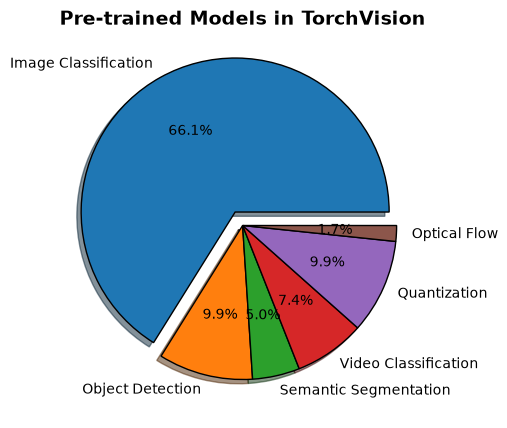

In [3]:
display(Markdown("*Pie Chart of Models in TorchVision by Classification*"))

# Remove All Models count in preparation of pie chart
df = df[df["Classification"] != "All Models"]

# Pie chart with Model count in different classes
plt.figure(figsize=(5, 5))
plt.title("Pre-trained Models in TorchVision", fontsize=14, fontweight="bold")
plt.pie(
    df["Num Models"],
    labels=df["Classification"],
    explode=[0.1 if c == "Image Classification" else 0 for c in df["Classification"]],
    autopct="%1.1f%%",
    wedgeprops={"edgecolor": "black"},
    shadow=True,
)
plt.show()

## 3. Inspecting MobileNetV3 <a id="3-inspecting-mobilenetv3"></a>

This section inspects a few different aspects of the model MobileNetV3 included in TorchVision Models. This inspection is done via `inspect` module in Python. Following are looked at further:

- Source Files
- Classes in MobileNetV3
- Classes derived from nn.Module
- Methods in MobileNetV3 class
- Source

**Source Files**: Each of these models has a source file that includes main class for the model architecture plus other supporting classes.

**Classes in MobileNetV3**: This is a small list of classes for the architecture of the model as well as storing the weights.

In [4]:
source_file = inspect.getfile(tv_models.mobilenetv3)
display(
    Markdown(
        "*1. Source File for MobileNetV3 architecture (from the current environment)*"
    )
)
print(source_file)

display(Markdown("*2. Classes in MobileNetV3*"))
classes_in_mv3 = inspect.getmembers(tv_models.mobilenetv3, inspect.isclass)
display(classes_in_mv3)

*1. Source File for MobileNetV3 architecture (from the current environment)*

/opt/anaconda3/envs/pytorch-learning/lib/python3.13/site-packages/torchvision/models/mobilenetv3.py


*2. Classes in MobileNetV3*

[('Any', typing.Any),
 ('Conv2dNormActivation', torchvision.ops.misc.Conv2dNormActivation),
 ('ImageClassification', torchvision.transforms._presets.ImageClassification),
 ('InvertedResidual', torchvision.models.mobilenetv3.InvertedResidual),
 ('InvertedResidualConfig',
  torchvision.models.mobilenetv3.InvertedResidualConfig),
 ('MobileNetV3', torchvision.models.mobilenetv3.MobileNetV3),
 ('MobileNet_V3_Large_Weights', <enum 'MobileNet_V3_Large_Weights'>),
 ('MobileNet_V3_Small_Weights', <enum 'MobileNet_V3_Small_Weights'>),
 ('SElayer', torchvision.ops.misc.SqueezeExcitation),
 ('Sequence', collections.abc.Sequence),
 ('Tensor', torch.Tensor),
 ('Weights', torchvision.models._api.Weights),
 ('WeightsEnum', <enum 'WeightsEnum'>),
 ('partial', functools.partial)]

**Classes derived from nn.Module**: These are the main model class as well as layers. MobileNetV3 and InvertedResidual are the main classes from neural network perspective.

In [5]:
display(Markdown("*3. Classes derived from nn.Module*"))
module_subclasses = [
    (cls, obj) for cls, obj in classes_in_mv3 if issubclass(obj, nn.Module)
]
display(module_subclasses)

mobnetv3_cls = tv_models.mobilenetv3.MobileNetV3

display(Markdown("*4. MRO (inheritance) for MobileNetV3 class*"))
display(inspect.getmro(mobnetv3_cls))

*3. Classes derived from nn.Module*

[('Conv2dNormActivation', torchvision.ops.misc.Conv2dNormActivation),
 ('ImageClassification', torchvision.transforms._presets.ImageClassification),
 ('InvertedResidual', torchvision.models.mobilenetv3.InvertedResidual),
 ('MobileNetV3', torchvision.models.mobilenetv3.MobileNetV3),
 ('SElayer', torchvision.ops.misc.SqueezeExcitation)]

*4. MRO (inheritance) for MobileNetV3 class*

(torchvision.models.mobilenetv3.MobileNetV3,
 torch.nn.modules.module.Module,
 object)

**Methods in MobileNetV3 class**: You will find the required `__init__` and `forward` methods. There is also a `_forward_impl` where the actual forward implementation resides.

**Source**: Source can be printed from inspect.getsourcelines()

In [6]:
display(Markdown("*5. Methods in MobileNetV3 class*"))
mobnetv3_functions = inspect.getmembers(mobnetv3_cls, inspect.isfunction)
mobnetv3_methods = [
    meth for meth, _ in mobnetv3_functions if meth in mobnetv3_cls.__dict__
]
display(mobnetv3_methods)

display(Markdown("*6. A few Source Lines from MobileNetV3 class*"))
lines, _ = inspect.getsourcelines(mobnetv3_cls)
display([line.rstrip() for line in lines[0:10]])

*5. Methods in MobileNetV3 class*

['__init__', '_forward_impl', 'forward']

*6. A few Source Lines from MobileNetV3 class*

['class MobileNetV3(nn.Module):',
 '    def __init__(',
 '        self,',
 '        inverted_residual_setting: list[InvertedResidualConfig],',
 '        last_channel: int,',
 '        num_classes: int = 1000,',
 '        block: Optional[Callable[..., nn.Module]] = None,',
 '        norm_layer: Optional[Callable[..., nn.Module]] = None,',
 '        dropout: float = 0.2,',
 '        **kwargs: Any,']

## 4. Creating MobileNetV3 Model with pre-trained Weights <a id="4-creating-mobilenetv3-model-with-pre-trained-weights"></a>

To create a MobileNetV3 model of the size you want (small or large), there are some factory functions (or model builder functions) in torchvision.models namespace. These are:

- mobilenet_v3_large
- mobilenet_v3_small

As the names suggest, two different architectures (large vs. small) are used. There are different sets of weights for the larger version, but DEFAULT gives the best version.

In both cases, weights are loaded into the model with load_state_dict() method from nn.Module base class. The state dictionary (of all the trainable parameters and non-trainable buffers) is read from .pth files. These weights files are downloaded from pytorch.org (the download links are in the weight classes). By default, the progress parameter in these model builder functions is set to True, meaning, they show downloading progress bar.

The default large weights for MobileNetV3 model are about 21MB. The file (.pth) is saved by default in the .cache folder (in the torch/hub folder), unless TORCH_HOME environment variable is set to a different folder.

First time when the model weights are downloaded, you will see something like this:

```
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /Users/rammareddy/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth
100%|██████████| 21.1M/21.1M [00:00<00:00, 49.5MB/s]
```

In [7]:
def create_pretrained_model() -> nn.Module:
    return tv_models.mobilenet_v3_large(
        weights=tv_models.MobileNet_V3_Large_Weights.DEFAULT, progress=True
    )


mobilenetv3_model = create_pretrained_model()

display(
    f"Current torch.hub directory where .pth files are saved: {torch.hub.get_dir()}"
)

'Current torch.hub directory where .pth files are saved: /Users/rammareddy/.cache/torch/hub'

# III. Model Architecture <a id="iii-model-architecture"></a>


## 5. Architecture of MobileNetV3 <a id="5-architecture-of-mobilenet-v3"></a>

Full listing of the model architecture can be displayed by using print() or display() on the model object. These are some highlights of the MobileNetV3 architecture:

At the highest level, model has three sections:

1. features
2. avgpool
3. classifier

The features section is the largest and contains:

1. Initial Sequential layer
2. Multiple Inverted Residual Blocks (15 in this case - the large version of MobileNetV3)
3. A final Conv2dNormActivation layer

The avgpool section readies the output from features section to be usable by the classifier:

1. One AdaptiveAvgPool2d
2. A flatten layer (not shown, used in forward() method, not defined in `__init__` of the model class)

The classifier section outputs the predictions (1000 classes from these weights, trained on ImageNet):

1. First Linear layer
2. Activation layer: Hardswish (a version of ReLU)
3. Dropout layer with 0.2 probability
4. Final Linear layer with 1000 output features 


In [8]:
display(Markdown("*Architecture of MobileNetV3 Model*"))
# display(mobilenetv3_model)
# help(mobilenetv3_model)

config = {"input_size": (256, 3, 224, 224)}

summary = torchinfo.summary(model=mobilenetv3_model, input_size=config["input_size"])
print(summary)

*Architecture of MobileNetV3 Model*

Layer (type:depth-idx)                             Output Shape              Param #
MobileNetV3                                        [256, 1000]               --
├─Sequential: 1-1                                  [256, 960, 7, 7]          --
│    └─Conv2dNormActivation: 2-1                   [256, 16, 112, 112]       --
│    │    └─Conv2d: 3-1                            [256, 16, 112, 112]       432
│    │    └─BatchNorm2d: 3-2                       [256, 16, 112, 112]       32
│    │    └─Hardswish: 3-3                         [256, 16, 112, 112]       --
│    └─InvertedResidual: 2-2                       [256, 16, 112, 112]       --
│    │    └─Sequential: 3-4                        [256, 16, 112, 112]       464
│    └─InvertedResidual: 2-3                       [256, 24, 56, 56]         --
│    │    └─Sequential: 3-5                        [256, 24, 56, 56]         3,440
│    └─InvertedResidual: 2-4                       [256, 24, 56, 56]         --
│    │    └─Sequential: 3-6   

## 6. Inverted Residual Block <a id="6-inverted-residual-block"></a>

A primary architectural component of MobileNetV3 is a block called Inverted Residual. Each block differs based on the configuration, but following is the typical structure:

1. Each Inverted Residual is Sequential block of 2 or 3 Conv2dNormActivation layers.

2. Each Conv2dNormActivation (as name suggests) is a shortcut for a collection 3 layers that you see repeated often in CNN architectures:

- a Conv2d layer
- a BatchNorm2d layer
- an activation layer (e.g. ReLU)

3. The inputs to outputs in the convolutions layers will start low and go up and then go down (for example):

16 -> 64 -> 24
24 -> 72 -> 24
40 -> 240 -> 80

4. Some InvertedResidual blocks have SqueezeExcitation blocks. This is a collection of 4 layers. First 'squeeze' - with AdaptiveAvgPool2d with an output size of 1. Then conv -> activation -> conv -> activation layers.

In [9]:
display(
    Markdown(
        "*An InvertedResidual block with 3 Conv2dNormActivation blocks and 1 SqueezeExcitation block:*"
    )
)
display(mobilenetv3_model.features[4])

*An InvertedResidual block with 3 Conv2dNormActivation blocks and 1 SqueezeExcitation block:*

InvertedResidual(
  (block): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(72, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Conv2dNormActivation(
      (0): Conv2d(72, 72, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2), groups=72, bias=False)
      (1): BatchNorm2d(72, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): SqueezeExcitation(
      (avgpool): AdaptiveAvgPool2d(output_size=1)
      (fc1): Conv2d(72, 24, kernel_size=(1, 1), stride=(1, 1))
      (fc2): Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1))
      (activation): ReLU()
      (scale_activation): Hardsigmoid()
    )
    (3): Conv2dNormActivation(
      (0): Conv2d(72, 40, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(40, eps=0.001, momentum=0.01, affine=True,

## 7. Classifier Block <a id="7-classifier-block"></a>

This is the final block in MobileNetV3 model ('classifier Head'). It takes a familiar structure of a classifier block:

Fully Connected Layer -> Activation Layer -> Dropout -> Final Fully Connected Layer with outputs for number of classes

Which in this case is (all these layers inside a Sequential so that they execute one after the other):

Sequential(Linear -> Hardswish -> Dropout -> Linear)

After the flattening of the output from features block, you come to 960 input features for the first linear layer. After an activation layer and a dropout of 0.2 probability, final Linear layer outputs 1000 numbers. These correspond to 1000 classes from the ImageNet image classes.

In [10]:
display(Markdown("*Classifier Head - the final block of MobileNetV3*"))
display(mobilenetv3_model.classifier)

*Classifier Head - the final block of MobileNetV3*

Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)

Classifier block has just two Linear layers. These two layers have about 2.5 million parameters, surprisingly. That's because these are 'fully connected' layers.

**8.1 First Linear Layer:**

`(0): Linear(in_features=960, out_features=1280, bias=True)`

This Linear layer has 960 inputs (so, these are: x0, x1, x2 ... x959). So, there will be 960 weights (w0, w1, w2, ... w959) and 1 bias. And there are 1280 outputs from this layer. That means there are 1280 units ('neurons'), each with 960 weights and 1 bias. 

So, total parameters (weights+biases) at this linear layer = (960 + 1) * 1280 = 1,230,080

**8.2 Activation and Dropout Layers:**

```
(1): Hardswish()
(2): Dropout(p=0.2, inplace=True)
```

These layers don't have any parameters. They use a standard predefined algorithm, not weights. Hardswish() is like ReLU(); while ReLU() substitutes all the negative values with 0, Hardswish() substitutes values `x <= -3` with 0. For `-3 < x < 3`, it uses the formula x·(x+3)/6. So, -2 becomes -2(-2+3)/6 = -0.3333, and 1 becomes 1(1+3)/6 = 0.6667. Values `x >= 3` are left unchanged, like ReLU().

Similarly Dropout doesn't use any weights. Each value has 20% probability of getting set to 0 (if p=0.2) and the remaining values are multiplied by 1/(1-p). Here that value is 1/(1-0.2) = 1/0.8 = 1.25. So, each of the unchanged values are multiplied by 1.25. 

**8.3 Second Linear Layer:**

`(3): Linear(in_features=1280, out_features=1000, bias=True)`


## 8. Number of Parameters <a id="8-number-of-parameters"></a>

Total number of parameters are the count of all the weights and biases at all the layers in the model. The MobileNetV3 model has two large sections with parameters:

- features layers 
- classifier layers

Total number of parameters are about 5.5 million for the MobileNetV3 (large) model. Features layers have about 3 million parameters and Classifier layers have about 2.5 million parameters. Features block has large number of layers (the ones with parameters are Conv2d and BatchNorm2d). In the Classifier block, only Linear layers have parameters.



In [11]:
def param_count(model: nn.Module, section: str = "") -> int:
    """Counts parameters for a named layer group.

    Args:
        model: Model object.
        section: Prefix of the named layers. For example, features layers might start
            with the word 'features'; classifier layers might start with 'classifier'.
            Empty string will give total parameter count.

    Returns:
        Number of parameters.
    """
    params = [
        param for name, param in model.named_parameters() if name.startswith(section)
    ]
    total = 0
    for param in params:
        total += param.numel()
    return total


display(Markdown("*Parameter Count in MobileNetV3 (large)*"))

param_dict = {
    "total params": param_count(mobilenetv3_model),
    "feature params": param_count(mobilenetv3_model, "features"),
    "classifier params": param_count(mobilenetv3_model, "classifier"),
}

df = pd.DataFrame(param_dict.items(), columns=["metric", "value"])
display(Markdown(df.to_markdown(index=False)))

*Parameter Count in MobileNetV3 (large)*

| metric            |   value |
|:------------------|--------:|
| total params      | 5483032 |
| feature params    | 2971952 |
| classifier params | 2511080 |

This is the last linear layer. The parameters here are:

(1280 + 1) * 1000 = 1,281,000

**4. Total Parameters at Classifier Layers:**

Linear 1 = 1,230,080
Linear 2 = 1,281,000

Total = 2,511,080

In [12]:
# 2. Parameters in the Classifier Layers

display(Markdown("*Parameters in Classifier Layer:*"))
params = [
    (name, param)
    for name, param in mobilenetv3_model.named_parameters()
    if name.startswith("classifier")
]
for name, param in params:
    print(f"{name}: {param.numel():,}")

*Parameters in Classifier Layer:*

classifier.0.weight: 1,228,800
classifier.0.bias: 1,280
classifier.3.weight: 1,280,000
classifier.3.bias: 1,000


## 9. Change Layers and Turn off Autograd <a id="9-turn-off-autograd-at-features-layers"></a>

In fine-tuning, changes to the model architecture involves two things:

- Creating a new classifier layer
- Turning on requires_grad for select layers

The original model was trained to recognize 1000 classes of images. So, final classifier layer (an nn.Linear layer) has 1000 output features for that layer. The new fine-tuned model only outputs 10 classes (for 10 digits). So, that Linear layer needs to replaced with 10 out features (the in-features remain the same as before, so that none of the architecture before this layer changes).

Then we would first turn off the requires_grad for all the parameters in the features layers above the classifier layers. After that we would turn on according to our fine-tuning scenario. We might turn on requires_grad for only a few features layers or the entire model. Accordingly the parameters (weights and biases) in those layers will be modified during the fine-tuning training loop. Remaining weights (with requires_grad=False) will not change - they will be the same weights as in the original MobileNetV3 model.

In [13]:
def add_new_final_classifier_layer(self) -> None:
    """
    A new classifier layer is added with the given number of output classes.
    """
    # Final Linear layer of the classifier
    final_layer = self.model.classifier[-1]
    # Keep the input features coming into this final layer
    in_features = final_layer.in_features

    # Create new final classifier layer
    new_classifier_output_layer = nn.Linear(
        in_features=in_features,
        out_features=self.new_out_features,
        bias=True,
    )
    # Replace final classifier layer
    self.model.classifier[-1] = new_classifier_output_layer

In [14]:
def turn_off_gradients_all_features_layers(self) -> None:
    for param in self.model.features.parameters():
        param.requires_grad = False


def turn_on_gradients_for_selected_layers(self):
    """
    All model layers are tuned, if num_layers_to_tune is -1.
    Otherwise, only the last num_layers_to_tune feature layers are tuned.
    """
    if self.num_layers_to_tune == -1:
        for param in self.model.parameters():
            param.requires_grad = True
    else:
        for i in range(self.num_layers_to_tune):
            for param in self.model.features[-i].parameters():
                param.requires_grad = True

# IV. Data for Fine-Tuning <a id="iv-data-for-fine-tuning"></a>



## 9. Fine-tuning Scenario and Options <a id="9-finetuning-scenario"></a>

The weights downloaded here for MobileNetV3 reflect the training on ImageNet1k, which has exactly 1000 non-overlapping classes of images. Hand-written digits are not part of this dataset. So, if you ask for inference on these images of 0-9 handwritten digits, the model will predict one of the 1000 classes it was trained on. But from that training using 1.2 million images, the model would have learned the edge detection and other low-level filters. If all we want from our new model is to recognize digits from 0 through 9, we can train the model (all layers or selective layers) with a dataset of handwritten digit images and change the classifier output from 1000 to 10.

Remainder of this notebook looks at various ways of achieving this finetuning.

**Options for Fine-tuning**

**EMNIST Dataset**

Here the finetuning is done for digits (0-9) from the EMNIST dataset. This is a dataset available for download from torchvision.datasets. It comes with several splits - and the split that we are interested in is digits.

In [15]:
# Download the raw data files if needed and create training and testing datasets

# train_val_dataset is to be split into train_dataset and val_dataset
train_val_dataset = datasets.EMNIST(
    "./data/EMNIST", split="digits", train=True, download=True
)

# test_dataset will be used to test the final accuracy after the model
# training is completed
test_dataset = datasets.EMNIST(
    "./data/EMNIST", split="digits", train=False, download=True
)

print(type(train_val_dataset))

<class 'torchvision.datasets.mnist.EMNIST'>


## 11. Fine-tuning Data (MNIST Digits Datasets) <a id="11-information-about-digits-datasets"></a>

**10.1 Dataset Type and MRO**

The dataset used here is from torchvision.datasets.mnist module: EMNIST. As shown in the MRO (Method Resolution Order) for this class, all the torchvision datasets have Dataset as the ultimate base class. On the way, they also have VisionDataset (defined in torchvision) as base class. For some datasets, VisionDataset is the immediate base class; and for some it is one more level deep (for example: EMNIST -> MNIST -> VisionDataset).

Since EMNIST is a Dataset, it implements `__len__` and `__getitem__` methods. From these methods we can get the length (number of samples) and a particular sample via index, i.e. `[idx]`.

**10.2 Number of Samples**

While initializing a dataset, we can set train=True or False to make training dataset or test dataset. In this case there are 240k training samples and 40k test samples. All these are images of hand written digits from 0-9.



In [16]:
# 1. Dataset Type and MRO

ds_class = type(train_val_dataset)
display(Markdown("*Class for datasets:*"))
display(ds_class)

display(Markdown(f"*MRO for {ds_class}:*"))
display(inspect.getmro(ds_class))

# 2. Number of Samples

train_samples = len(train_val_dataset)
test_samples = len(test_dataset)

display(Markdown("*Number of Samples*:"))
display(
    Markdown(
        f"Samples in Training Dataset: {train_samples:,} <br>\
        Samples in Test Dataset: {test_samples:,}"
    )
)


*Class for datasets:*

torchvision.datasets.mnist.EMNIST

*MRO for <class 'torchvision.datasets.mnist.EMNIST'>:*

(torchvision.datasets.mnist.EMNIST,
 torchvision.datasets.mnist.MNIST,
 torchvision.datasets.vision.VisionDataset,
 torch.utils.data.dataset.Dataset,
 typing.Generic,
 object)

*Number of Samples*:

Samples in Training Dataset: 240,000 <br>        Samples in Test Dataset: 40,000

**10.3 A sample Images**

When a Dataset is accessed with an `[index]` for a sample, it returns a tuple of (image, label). For these datasets, no transformation has been done by setting `transform` parameter to a set of transforms including changing the image array to a tensor. So, at this point, the dataset still returns an image that can be displayed by display() or imshow() from matplotlib. All the digit images are of size 28x28. Note that torchvision's EMNIST images are stored transposed (rotated and flipped compared to MNIST), so the sample digit below appears mirrored until a transform corrects it.

In [17]:
# 3. A sample Images
def show_sample_imgs(
    ds: Dataset, transformed: bool = False, ds_idx_list: list[int] = None
) -> None:
    """Display image grid with label, img, prediction."""
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(8, 4))

    max_idx = len(ds) - 1

    ds_idxs = []
    if ds_idx_list:
        ds_idxs = ds_idx_list
    else:
        ds_idxs = [random.randint(0, max_idx) for i in range(10)]
    samples = [ds[ds_idx] for ds_idx in ds_idxs]
    for idx, ax in enumerate(axes.flatten()):
        img, label = samples[idx]
        if transformed:
            img = img.permute(1, 2, 0).clamp(0, 1)

        ax.axis("off")
        ax.imshow(img, cmap="gray")

        ax.text(
            0,
            1.05,
            f"label={label}",
            color="blue",
            transform=ax.transAxes,
        )

    plt.show()

*Sample images from MNIST Digits Dataset (in the dataset they appear rotated/flipped*

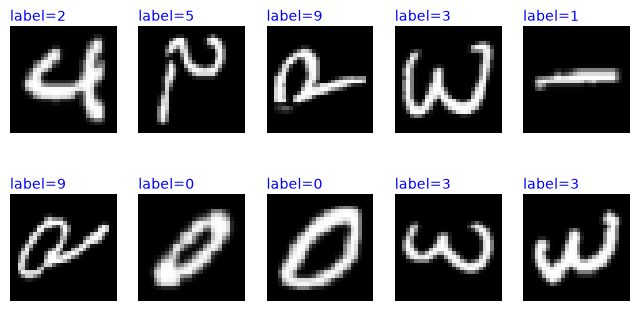

In [18]:
display(
    Markdown(
        "*Sample images from MNIST Digits Dataset (in the dataset they appear rotated/flipped*"
    )
)
show_sample_imgs(ds=train_val_dataset)

# V. Data Preparation <a id="v-data-preparation"></a>



## 12. Split into Traning and Validation Datasets <a id="12-split-into-traning-and-validation-datasets"></a>

We have Training and Testing Datasets downloaded from MNIST Dataset class of torchvision. These sets contain 240k samples for training and 40k samples for testing. There is no separate validation set. I will take 40k from training set and make it validation set. So, following will be the sizes of datasets after the split:

- training: 200k
- validation: 40k
- testing: 40k

The ratios are roughly 70% training, 15% for validation, and 15% for testing (though rounding off the sizes to nearest 10k, makes the actual percentages slightly different).

In [19]:
def split_train_val(
    dataset: Dataset, lengths: tuple[int, int]
) -> tuple[Subset, Subset]:
    """Splits a dataset into just two subsets by using the numbers provided in lengths tuple.

    Args:
        dataset: The Dataset to be split.
        lengths: Number of samples in each dataset (total should equal to the samples in the
        dataset to be split.

    Returns:
        tuple[Subset, Subset]: Two Subset objects (Subset is derived from Dataset)
    """
    train_dataset, val_dataset = random_split(dataset, lengths=lengths)
    return train_dataset, val_dataset

In [20]:
# Split the initial 240k dataset

train_dataset_size = 200000
val_dataset_size = 40000
train_dataset_untransformed, val_dataset_untransformed = split_train_val(
    dataset=train_val_dataset, lengths=(train_dataset_size, val_dataset_size)
)

# Sizes of datasets after splitting

display(Markdown("*Sizes of traning and validation datasets after splitting*"))
display(
    Markdown(
        f"Training Dataset: {len(train_dataset_untransformed):,} <br> \
                 Validation Dataset: {len(val_dataset_untransformed):,}"
    )
)

*Sizes of traning and validation datasets after splitting*

Training Dataset: 200,000 <br>                  Validation Dataset: 40,000

## 13. Transformations for Datasets <a id="13-transformations-for-datasets"></a>

Current datasets have inputs (images) in the PIL.Image format. For PyTorch training to work a few different kinds of transformations need to be performed on the data:

Documentation for weights:
https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_large.html#torchvision.models.MobileNet_V3_Large_Weights

- The digits in EMNIST dataset are grayscale images. So, these images don't have 3 channels (RGB), but just 1 channel. The MobileNetV3 model has been trained with images of 3 channels. So, we need to introduce 3 channels into these images.
- The digits in EMNIST data set are 28x28. For training, the ImageNet images have been resized to 224x224 in MobileNetV3. We need to resize EMNIST images as well.
- Original dataset is transposed, as you can see from the digit display in a previous cell (this is because of a historical reason in dataset creation). This needs to be fixed.

- Images need to be transformed into tensors. The numbers in PyTorch are tensors (for autograd capability, ability to run on GPUs, etc.).
- For the deep learning algorithms to be effective, these numbers should be normalized. The pixel RGB values range between 0-255. Use the mean and standard deviation values from the ImageNet dataset. Mean and std for normalization are mentioned in the documentation.

- Then we can add more transformations to give small random variations to the images so that model sees more images during training.

**Normalization**

In order to normalize the images from the dataset, you need the mean and std of the overall dataset. You can obtain this information from .transforms() method of the weights class. This also provides the image size that was used in training the backbone model.

In [21]:
# Original size: 28x28
# MobileNetV3 is trained with 224x224.
new_image_size = [224, 224]

# For normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]


**Basic Transformations**

All the images need to go through some basic transformations for them to be successfully used in the training process (or the fine-tuning process here). These transformations are listed below. First one is Grayscale that outputs 3 channels. The images in the digits dataset are just one channel, but the torchvision models use 3-channels (RGB). Next transformation is Resize(). The images in digits dataset are 28x28. The MobileNetV3 has been trained with 224x224 size. So, these hand-written digits images need to be resized to that in order to use the learning from the previous training.

The ToImage() converts the PIL Image to Tensor. The PIL Image follows the (H, W, C) format - where the Channels are at the end. After conversion, the Channels are moved to the begininning via .permute() method on Tensors. So, the output of this step will be a tensor or shape (C, H, W).

As shown above, the images in the digits dataset are flipped and rotated (this is one of quirks of the original dataset). Once the tensor has been made, each image tensor needs to be transposed. This is done with the Lambda() transfromation.

In V2 of transforms, we do conversion to tensor and conversion to float32 and scaling in two separate steps. Here Dtype cast the original uint8 (i.e. 0-255 number) to float32 and it is scaled (the values are now 0-1, instead of 0-255). And finally these numbers are normalized with Normalize() transformation using the mean and std of the entire set.

These basic transformations are done on all the datasets used in this process - training, validation, and testing. These image tensors are now ready to be used in training or inference.

In [22]:
basic_transformations = [
    T.Grayscale(num_output_channels=3),
    T.Resize(size=new_image_size),
    T.ToImage(),
    T.Lambda(lambda img: img.transpose(-2, -1)),
    T.ToDtype(dtype=torch.float32, scale=True),
    T.Normalize(imagenet_mean, imagenet_std),
]

# Call this eval_transformation which can be used for both validation and test.
validation_transformations = T.Compose(basic_transformations)

**Augmentation Transformations**

In addition, we would want to do some addition transformations on training dataset. These transformations provide the model with additional opportunities to learn. They are essentially new samples, though based on the existing samples. Hence, they are called augmentation transformations. These transformations could be rotating the image slightly in a random way or adjust the sharpness or flip it, etc.

For most of the image models, this slight transformation actually aids in the model learning and correctly inferring the images that might have slight changes. However, as we can see below, for digit dataset (this fine-tuning), these transformations hurt. For example, if 6 is rotated, it would look like 9 and vice versa. That confuses the model. I tried training with a few of these transformations and in different combinations. All of them hurt the accuracy of the model a lot or at least a little bit. So, I completely removed these augmentation transformations on training set (did the basic tranformations, which are needed). Even without this extra help, you can see below that full model finetuning has reached over 99% accuracy with just 30 epochs worth of training.

In [23]:
augmentation_transformations = [
    # T.RandomRotation(degrees=5),
    # T.RandomAdjustSharpness(sharpness_factor=1.5, p=0.3),
    # T.ColorJitter(brightness=0.1, contrast=0.1),
    # T.RandomVerticalFlip(p=1.0),
    T.RandomAffine(degrees=0, shear=10, translate=(0.1, 0.1)),
    T.RandomPerspective(distortion_scale=0.1, p=0.5),
]

training_transformations = T.Compose(
    augmentation_transformations + basic_transformations
)

## 14. Apply Transformations to Datasets <a id="14-apply-transformations-to-datasets"></a>

Typically the transformations can be applied right at the time of download the data from the EMNIST class. It has transforms as one of the parameters. However, in this case we have split the training dataset into training and validation datasets using random_split() function. This function spits out two Subset objects (Subset is a derived class of Dataset class). Each of these Subset objects do not split the original Dataset into two, but instead they keep a list indices of the samples for their use (either training or validation). So, if we used a transformation on the original dataset, then both the datasets will get those transformations. Which is not what we want generally - we want the the validation dataset to have basic transformations but training dataset also have augmentation transformation in order to improve the training. In this case though (for the reasons explained above - rotating a 6 would make it 9, etc.), both of them use the same basic transformations.

However, if you genuinely wanted different transformations, here is a quick way of writing a custom Dataset. It requires just two methods outside the `__init__`: `__getitem__` and `__len__`. First one lets you access a sample at an index via [] - this provides the functionality of an iterator (old style Python). And, of course, `__len__` gives you the length of the dataset with Python built-in len() function.





```
class TransformedDataset(Dataset):
    def __init__(self, dataset: Dataset, transform: T.Transform):
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        img, label = self.dataset[index]
        img_t = self.transform(img)
        return img_t, label

    def __len__(self) -> int:
        return len(self.dataset)
```

In [24]:
train_dataset = TransformedDataset(
    dataset=train_dataset_untransformed, transform=training_transformations
)
val_dataset = TransformedDataset(
    dataset=val_dataset_untransformed, transform=validation_transformations
)

**Images after transformation**

Below the digits images are shown after the transformations have been applied. In the first case, just the base transformations are applied. This is validation dataset. As you can see, now the digits are recognizable - they are no longer flipped and rotated as in the original dataset. These are also tensfors with (C, H, W) shape. the show_sample_imgs() does the appropriate .permute(1, 2, 0) so that Channels (RGB) are moved to the end which is how matplotlib expects its images.

If you see the second set of images below, they are from training dataset. Both basic and augmentation transformations are applied to these images. You can see that the images are unrecongnizable as regular digits. Image of a cat or dog, etc. would still look like a cat or a dog if if it is rotated/flipped/etc. However, here the digits become more difficult to understand if they are massively transformed (for example, rotating a 6 would begin to look like 9 and vice-versa). In the tests these augmentation transformations have not been helping the model learn more (instead they were hurting). So, for the fine-tuning below, these augmentation transformations have not been applied to the training dataset (only the basic transformations were applied).


*Images from Validation Dataset with **(Basic) Transformations** applied*

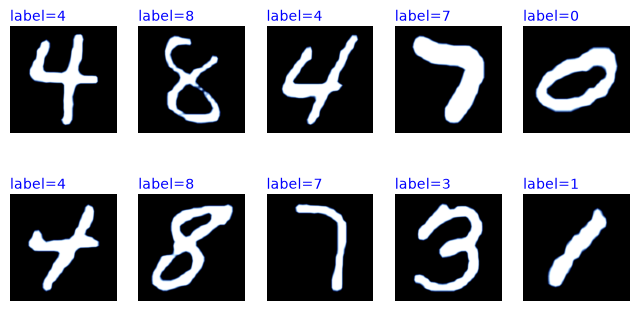

*Images from Training Dataset with **(Basic+Augmentation) Transformations** applied*

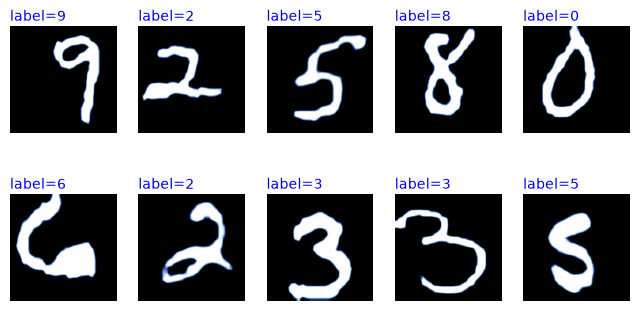

In [25]:
# Transformed Validation Dataset
display(
    Markdown(
        "*Images from Validation Dataset with **(Basic) Transformations** applied*"
    )
)
show_sample_imgs(ds=val_dataset, transformed=True)

# Transformed Training Dataset
display(
    Markdown(
        "*Images from Training Dataset with **(Basic+Augmentation) Transformations** applied*"
    )
)
show_sample_imgs(ds=train_dataset, transformed=True)


## 15. Prepare DataLoaders <a id="15-prepare-traning-and-validation-dataloaders"></a>

Datasets give one sample at a time. DataLoaders use datasets to package samples in batch size and pass it to model for inference in the training loop. Apart from dataset, following properties can be tuned for Dataloaders:

- shuffle: When the samples are sent to the model, the order of samples can be shuffled if this parameter is set to True. Shuffling the samples during training is valuable for model learning (some type of order based learning will be avoided). In evaluation dataloaders (like val_dataloader and test_dataloader), this flag (shuffle) is not helpful since the learning has already been done.

- batch_size: depending on the power of the hardware available, the batch_size can be set. This helps with the amount of time it takes to complete the training. The batch_size is typically a multiple of 16, like: 32, 64, 128, 256, etc. Higher batch_size speeds up the training, upto the size that the available hardware can handle; above that, it will have a negative effict.

- num_workers: typically GPUs will be sitting waiting for CPUs to feed the samples to it for inference/training. If lot of CPU cores are available, num_workers can be increased. By default, num_workers on a dataloader is set to 0. If there are 40 CPU cores, the num_workers could be 30. And each of them will make 2 batches ready, if the default prefect_factor is used. 

- prefetch_factor: And by default prefetch_factor = 2, which means each worker will work on making 2 batches ready. Number of workers could be same as the number of CPU cores, after some cores are left for other processing. If the batch_size is 256, (and num_workers=30 and prefetch_factor=10), the number of samples that are ready with these settings is: 30x10x256 = 76,800. Since the total number of samples here are in thousands, not millions, the num_workers, prefetch_factor, and pin_memory settings are not used for this project.

- pin_memory: On CUDA devices, setting this to True will make the system place the samples in an area that is non-pageable when CPU is processing it. This can be transferred to GPU memory much faster than transferring from a pageable area. On MacbookPro (M4, M5) though, all the RAM is shared between CPUs and GPUs - so, this setting has no effect.

In [26]:
def prepare_dataloaders(batch_size: int = 256):
    """
    Prepares train, val, and test dataloaders.
    Train dataloader shuffles the samples. Val and Test dataloaders don't.
    batch_size passed to the class is used.
    """
    train_dataloader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        shuffle=True,
    )
    val_dataloader = DataLoader(
        dataset=val_dataset,
        batch_size=batch_size,
        shuffle=False,
    )
    # test_dataloader = DataLoader(
    #     dataset=test_dataset,
    #     batch_size=batch_size,
    #     shuffle=False,
    # )


prepare_dataloaders()

# VI. Training Preparation <a id="vi-training-preparation"></a>

Now that the model architecture has been finalized and data for fine-tuning is ready, we need to do the training (or fine-tuning). Following steps are needed for training preparation:

- Setup Device
- Prepare loss function and optimizer
- Create fine-tuning loop
- Create prediction/inference functionality

## 16. Setup Device <a id="16-setup-device"></a>

One of the first things to decide upon is the device. The training can be done on CPU - PyTorch/Tensors would work on CPU. However, for anything more than simplest of the trainings, it will take a very long time to complete. If you have a CUDA device available (on your computer or from Google Colab or from other sources), that can be used. This training has been done on MacBookPro (M4 Max 128GB). So, the device is Apple's MPS. Setup includes seeding both torch and cuda/mps libraries, so that same starting point is used for any random number generation.

Here I assume that if I am connected to a GPU outside my laptop, it will be a more powerful one. So, my preference in choosing a device is: cuda, mps, and finally cpu. This code is for this specific situation - if you know your device, it can also be set manually.

In [27]:
def choose_device(seed: int = 42) -> torch.device:
    """Returns the best device available."""
    torch.manual_seed(seed)
    device = torch.device("cpu")

    if torch.cuda.is_available():
        device = torch.device("cuda")
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    elif torch.backends.mps.is_available():
        device = torch.device("mps")
        torch.mps.manual_seed(seed)

    return device


device = choose_device()
print(device)

mps


## 17. Prepare loss function and optimizer <a id="17-prepare-loss-function-and-optimizer"></a>

Two important things that happen in a training loop are:

- Calculate the loss, i.e. what is the loss the loss when inference is run for current batch of inputs; and a backpropagation needs to be run to calculate the gradients at the weights to apportion that loss.
- And adjust the weights so that the loss maybe reduced when the inference is run for the next batch of inputs

The first task above is done with a loss function. PyTorch comes with several loss functions. Two most popular ones are mean squared error loss (MSELoss) function and CrossEntropyLoss function. For classification tasks, nn.CrossEntropyLoss() is used (this is classifying the images into one of the 10 digits). 

And for the second task above is done with an Optimizer. Two of the more popular optimizers are SGD and Adam. This takes two parameters: what parameters (weights and biases) of the model need to be adjusted. In normal training you will typically adjust all the parameters. So, you would set this to model.parameters(). However, since we are fine-tuning here, we set only a few layers (depending on the scenario) to have their parameters adjusted. For the weights in those layers we set requires_gra to True. So, filter those parameters and pass it on. Second parameter is learning_rate, which is typically set to some value like 0.1, 0.001, 0.001, 0.0001, etc. 

In [28]:
def create_loss_optim(self):
    """
    Loss function is CrossEntropyLoss for this classification task.
    Optimizer is SGD for the parameters that require gradient adjustments (fine-tuning)

    Returns:
        Loss function and optimizer.
    """
    self.loss_fn = nn.CrossEntropyLoss()
    self.optimizer = optim.SGD(
        filter(lambda p: p.requires_grad, self.model.parameters()),
        lr=self.learning_rate,
    )


## 18. Create Fine-Tuning Loop <a id="18-fine-tuning-loop"></a>


The fine-tuning loop is created in two steps. First there is a training_step() as shown in the cell below. This takes one batch of samples and calculates the loss for that batch and does a backpropagation and applies the adjustments from the optimizer. This is in the FinetuningDataModule class listed below. This class also has methods for one validation step and one testing step.

These step methods are run from the trainer (an instance of FinetuningTrainer class) object from the fit() method. This method has a loop like the following which runs the training for a specified number of epochs. In each epoch, a batch full of samples are obtained from the training dataloader and fed to training step, which does the loss calculation, backpropagation, and adjusting the model weights.

        for epoch in range(self.epochs):
            # Training
            loss_epoch = 0.0

            pbar_train = tqdm(
                iterable=self.train_dataloader,
                desc="training",
                unit="batches",
                leave=False,
            )
            loss_epoch_avg = 0.0

            for idx_train, (inputs, labels) in enumerate(pbar_train):
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                loss_step = self.module.training_step(
                    inputs=inputs, labels=labels
                )

In [29]:
def training_step(self, inputs: Any, labels: Any) -> Any:
    """
    One batch of samples are used to predict, calculate loss, backpropagate, and adjust
    parameters.

    Retuns:
        Loss: for this batch.
    """
    self.model.train()

    self.optimizer.zero_grad()
    preds = self.model(inputs)

    loss = self.loss_fn(preds, labels)
    loss.backward()
    self.optimizer.step()

    return loss

## 19. Create Prediction/Inference Functionality

In the evaluation step (unlike training step), which is used for validation and testing, we would want only the inference from the model. No training would happen to the model, i.e. the weights won't change during the inference stage. For this, we set model.eval() to put the model in evaluation mode and with torch.no_grad() there won't be any gradient calculations.

In [30]:
def evaluation_step(self, inputs: Any, labels: Any) -> Any:
    """
    Common method for Validation and Testing phase predictions for one
    batch of samples. Correct number of predictions is calculated.

    Returns:
        Number of correct predictions
    """
    self.model.eval()

    correct: int = 0
    with torch.no_grad():
        preds = self.model(inputs)
        _, pred_labels = preds.max(1)
        correct = (pred_labels == labels).sum()

    return correct

# VII. Fine-Tuning Classes <a id="vii-fine-tuning-classes"></a>


All the discussion above is consolidated below into five classes:

- FinetuningWeights
- FinetuningDataModule
- TransformedDataset
- FinetuningModule
- FinetuningTrainer
- FinetuningAnalytics

These are somewhat modeled on LightningDataModule and LightningModule, which are lot more powerful, but they hide all this implementation. Plus the metrics in this case limited to calculated loss and accuracy (`torchmetrics` library is not used). The training_step method contains the entire training to be executed in one epoch. And the code for fit() method is written in the FinetuningTrainer class.

In a typical LightningModule, you will define the model architecture. You will pass the number of layers of each type to construct a full model architecture. In our case, the model architecture is fully defined and available already (from MobileNetV3); in this case, the parameters are passed to the constructor to enable/disable layers for training.

The FinetuningTrainer class is also limited compared to Trainer class in Lightning - no profiling, etc. There is no separate selection of hardware: it chooses CUDA, if one is available, then looks for MPS (MacBookPro laptop), and then finally to CPU. Needless to say, this code doesn't provide callback functionality.

## 19. FinetuningWeights <a id="19-finetuningweights"></a>

In TorchVision, the weights classes themselves contain some useful information outside the classes, like the transformations used in the original training in using the original data set (in this case ImageNet). This transforms() method holds the mean and std of the original image dataset (ImageNet). One of the base transformation on the new image dataset is to transforms.Normalize(), which normalizes the values in the tensors by using mean and std. Instead of typing these numbers by hand, we can get it from the FinetuningWeights class.

Another important value is the size the images used in the original image set. ImageNet has images of all different sizes, but for training a model, you would need to standardize on an image size. This final image size can be obtained from `crop-size` applied to these images. In order to transfer the learning from the original training, we would need to make our new finetuning image dataset also the same size. The digits images are 28x28 and they will be resized to this size (224x224). Bringing all this information from the dataset means there is less room for mistakes.

In [31]:
code_text = inspect.getsource(FinetuningWeights)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningWeights:
    """
    These are the weights for the model that we are going to fine-tune.
    Like other classes here, the base model is assumed to be MobileNetV3.
    So, some things are very specific to this model and the available weights.

    It is not a very general set of classes (like Lightning) that work for a
    much broader set of models.

    Args:
        model_name: DEFAULT eights are obtained for this model name.
    """

    def __init__(self, model_name: str = "mobilenet_v3_large") -> None:
        self.model_name = model_name
        self.weights = tv_models.get_model_weights("mobilenet_v3_large").DEFAULT
        self.transforms = self.weights.transforms()

        self.metrics: dict = {}
        self.log()
        self.print_metrics()

    @property
    def mean(self) -> list[float]:
        """
        Mean for the training dataset used (ImageNet).

        Returns:
            3 floats corresponding to RGB.
        """
        return self.transforms.mean

    @property
    def std(self) -> list[float]:
        """
        Standard Deviation for the training dataset used (ImageNet).

        Returns:
            3 floats corresponding to RGB.
        """
        return self.transforms.std

    @property
    def image_size(self) -> list[int]:
        """
        Final size of the images used in training.

        Returns:
            List of 1 int, which is both height and width
        """
        return self.transforms.crop_size

    # -------
    # Logging
    # -------

    def log(self) -> None:
        """Metrics on the weights."""

        self.metrics["name"] = self.weights.name
        self.metrics["url"] = self.weights.url
        self.metrics["num categories"] = len(self.weights.meta["categories"])

        self.metrics["mean"] = self.mean
        self.metrics["std"] = self.std
        self.metrics["image size"] = self.image_size

    def print_metrics(self) -> None:
        display(Markdown("*`FinetuningWeights` is initialized. Metrics:*"))
        df = pd.DataFrame(self.metrics.items(), columns=["metric", "value"])
        display(Markdown(df.to_markdown(index=False)))

```

## 20. FinetuningDataModule <a id="20-finetuningdatamodule"></a>

FinetuningDataModule class contains all the necessary functionality for preparing the data. It downloads the training and test datasets. Then the training dataset is split into training and validation datasets. All three datasets will be made into three dataloaders with the given batchsize. This class also defines base and augmentation transformations. The base transformations are the required transformation to make the digits images ready for feeding into the training loop. They include adjusting the orientation in original images, resizing, converting the image data into tensors, and finally normalizing them. The augmentation transformation includes transformations to make new samples. Even though this functionality is added here, it is not used in preparing new images. Reason being the transformations are not helping (for example rotating is one of the typical augmentation applied; but if 6 is rotated, it's going to be 9 - heavily messing with the accuracy of the model).

In [32]:
code_text = inspect.getsource(FinetuningDataModule)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningDataModule:
    """
    Provides the data that is needed for this fine-tuning exercise. Datasets are
    downloaded from EMNIST and the train, val, and test datasets and dataloaders
    are made. For this class, the `digits` split is chosen. So, the images form
    10 classes for 10 digits (0 through 9).

    Args:
        root: the folder/path where the downloaded dataset files are stored.
        weights: a FinetuningWeights object that has mean, std, etc. values for
            the datasets.
        train_val_split: Split between training and validation datasets
        batch_size: for the dataloaders
    """

    def __init__(
        self,
        root: str | Path,
        weights: FinetuningWeights,
        train_val_split: Sequence[int | float] = (0.8, 0.2),
        batch_size: int = 256,
    ) -> None:
        # Passed parameters
        self.root = root
        self.train_val_split = train_val_split
        self.weights = weights
        self.batch_size = batch_size

        # Datasets
        self.train_dataset: Dataset = None
        self.val_dataset: Dataset = None
        self.test_dataset: Dataset = None

        # Data Loaders
        self.train_dataloader: DataLoader = None
        self.val_dataloader: DataLoader = None
        self.test_dataloader: DataLoader = None

        self.setup()

        # Metrics
        self.metrics: dict[str, Any] = {}
        self.log()
        self.print_metrics()

    def setup(self):
        """Prepare datasets and dataloaders"""
        self.prepare_datasets()
        self.prepare_dataloaders()

    def prepare_datasets(self):
        """
        Datasets are downloaded from torchvision (in this case EMNIST).
        Main training dataset is split into training and validation.
        Separate test dataset (non-training) is also downloaded.
        """
        # Training and validation datasets
        train_val_dataset = datasets.EMNIST(
            self.root, split="digits", train=True, download=True
        )

        # Split main dataset into train and validation datasets
        train_dataset_untransformed, val_dataset_untransformed = random_split(
            dataset=train_val_dataset, lengths=self.train_val_split
        )

        # Apply transformations separately to train and val
        self.train_dataset = TransformedDataset(
            dataset=train_dataset_untransformed,
            transform=self.train_transforms(),
        )
        self.val_dataset = TransformedDataset(
            dataset=val_dataset_untransformed, transform=self.eval_transforms()
        )

        # Download test dataset and apply transformations
        # Test dataset is not further split, so, we can apply transformations
        # right at the download.
        self.test_dataset = datasets.EMNIST(
            self.root,
            split="digits",
            train=False,
            download=True,
            transform=self.eval_transforms(),
        )

    def prepare_dataloaders(self):
        """
        Prepares train, val, and test dataloaders.
        Train dataloader shuffles the samples. Val and Test dataloaders don't.
        batch_size passed to the class is used.
        """
        self.train_dataloader = DataLoader(
            dataset=self.train_dataset,
            batch_size=self.batch_size,
            shuffle=True,
        )
        self.val_dataloader = DataLoader(
            dataset=self.val_dataset,
            batch_size=self.batch_size,
            shuffle=False,
        )
        self.test_dataloader = DataLoader(
            dataset=self.test_dataset,
            batch_size=self.batch_size,
            shuffle=False,
        )

    # ---------------
    # Transformations
    # ---------------

    def basic_transforms_list(self) -> list[Any]:
        """
        List of transformations to be applied all the incoming images
        (these are necessary transformations, does not include augmentations):

        - Grayscale: 1 channel gray digits will become 3-channel (RGB)
            gray digits.
        - Resize: Image resized to the size used in original model training
        - ToImage: Convert PIL image to Tensor
        - Lambda: transposes the image - a correction on the origninal
            MNIST images.
        - ToDtype: ToImage gives values in the range of 0-255 for pixels.
            Here, they are scaled to a number between 0.0 and 1.0 (a float32).
        - Normalize: Normalizes the tensor images with dataset mean and
            standard deviation.

        Returs:
            List of transformations
        """
        # Get mean, std, and image size from the weights
        return [
            T.Grayscale(num_output_channels=3),
            T.Resize(size=self.weights.image_size),
            T.ToImage(),
            T.Lambda(lambda img: img.transpose(-2, -1)),
            T.ToDtype(dtype=torch.float32, scale=True),
            T.Normalize(self.weights.mean, self.weights.std),
        ]

    def augmentation_transforms_list(self) -> list[Any]:
        """
        Some random transformations are applied to the training set of images.
        This helps model learn more because it sees subtle changes in the same
        original image.

        For MNIST dataset, augmentations are not used (explanation provided
            elsewhere).
        Just listed here for completeness.
        """
        return [
            # T.RandomRotation(degrees=5),
            # T.RandomAdjustSharpness(sharpness_factor=1.5, p=0.3),
            # T.ColorJitter(brightness=0.1, contrast=0.1),
            # T.RandomVerticalFlip(p=0.5),
            T.RandomAffine(degrees=0, shear=10, translate=(0.1, 0.1)),
            T.RandomPerspective(distortion_scale=0.1, p=0.5),
        ]

    def train_transforms(self) -> T.Compose:
        """
        Provides composed transforms to be used on training dataset.

        Typically, the entire list is made like this (augmentation+basic):
        `T.Compose(self.augmentation_transforms_list+self.basic_transforms_list)`

        However, in case of MNIST dataset, no augmentations are used.
        (explanation provided elsewhere)
        """
        return T.Compose(
            self.augmentation_transforms_list() + self.basic_transforms_list()
        )

    def eval_transforms(self) -> T.Compose:
        """
        Provides a composed transforms to be used in evaluation datasets:

        - validation dataset (in the training loop)
        - test dataset (for post-training)

        Returns:
            Composed transforms for eval.
        """
        return T.Compose(self.basic_transforms_list())

    # -------
    # Logging
    # -------

    def log(self) -> None:
        """Metrics on the data."""

        self.metrics["root"] = self.root
        self.metrics["batch_size"] = self.batch_size
        self.metrics["train_val_split"] = self.train_val_split

        self.metrics["train dataset samples"] = f"{len(self.train_dataset):,}"
        self.metrics["val dataset samples"] = f"{len(self.val_dataset):,}"
        self.metrics["test dataset samples"] = f"{len(self.test_dataset):,}"

    def print_metrics(self) -> None:
        """Prints metrics."""
        display(Markdown("*`FinetuningDataModule` is initialized. Metrics:*"))
        df = pd.DataFrame(self.metrics.items(), columns=["metric", "value"])
        display(Markdown(df.to_markdown(index=False)))

```

## 21. TransformedDataset <a id="21-transformeddataset"></a>

When a dataset is split using random_split as done here for splitting training dataset into training and validation, the dataset behind both of them will still be the same. The split datasets (a subclass of Dataset called Subset) simply contains list of sample indices that belong to training or validation (in each of the Subsets). So, if transformations are applied before splitting or after splitting, they will be applied to the same dataset. In order to solve that problem, this class named TransformedDataset is written. Here different transformations are applied to different datasets, at the time of `__getitem__` - meaning, training transformation is applied to training Subset and validation transformation is applied to validation Subset.

In [33]:
code_text = inspect.getsource(TransformedDataset)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class TransformedDataset(Dataset):
    """
    Specified transformation is applied as a sample is retrieved at a given
    index.

    Typically, transformations are applied when the original dataset is made.
    However, in this case, the same dataset is split into train and validation
    datasets by using random_split. This method yeilds two separate Subsets that
    share the same dataset in the back. Since transformations are different
    between, a separate class should apply individual transformations to each
    dataset. Hence the need for this TransformedDataset.

    Additional Note: In this specific case (MNIST) though no augmentation
    transformations are applied on train dataset. So, this class doesn't
    doesn't add anything (for this specific case). It is shown for completeness
    (and for the cases where transformations are different between training and
    validation datasets)

    Args:
        dataset: train or validation dataset
        transform: the transformation to be applied for that specific dataset
    """

    def __init__(self, dataset: Dataset, transform: T.Transform) -> None:
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        """
        Returns one sample at the provided index.

        Args:
            index: of the current sample.

        Returns:
            A tuple of (transformed image tensor and integer label for the
            class of the image)
        """
        image, label = self.dataset[index]
        image_transformed = self.transform(image)
        return image_transformed, label

    def __len__(self) -> int:
        """Number of samples in the dataset."""
        return len(self.dataset)

```

## 22. FinetuningModule <a id="22-finetuningmodule"></a>

This is the model manipulation class. Various finetuning options are supported from the num_layers_to_tune parameter. If this is set 0, only the classificaiton layer is tuned; meaning, the final classification fully connected layer (Linear) will changed to return 10 classes (for digits), instead of 1000 (for the original image classes). Second option is to set this parameter to a number between 1 and 16, depending on how many features blocks you want to tune. And finally, setting it to -1 will fine-tune the entire model (original weights will be the starting point, but training will modify them).

This class also provides methods for single step of training, validation, and testing. The full training loop will be elsewhere that calls these methods repeatedly. This class also contains appropriate loss and optimizer functions.

In [34]:
code_text = inspect.getsource(FinetuningModule)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningModule:
    """
    Base model that is being fine-tuned is downloaded and setup for fine-tuning.

    Args:
        weights: contains the name of the base model.
        new_out_featues: how many classes are there in the new fine-tune data.
            The original MobileNetV3 has 1000 classes; if this is being
            fine-tuned for digits data, the number of out features will be 10.
            This is used in the last Linear layer of the model classifier.
        num_layers_to_tune: supports different fine-tuning scenarios:
            - 0: classifier: only the classifier is changed and re-trained.
                Remaining weights are not changed.
            - 1-16: classifier+: In addition to new classifier, a specified
                number of layers are retrained.
            - -1: entire model: All layers in the model are re-trained.
                Training starts with the weights that are there in the original
                model; but all of them are changed during training.
        learning_rate: for the optimizer.
    """

    def __init__(
        self,
        weights: FinetuningWeights,
        new_out_features: int = 10,
        num_layers_to_tune: int = 0,
        learning_rate: float = 1e-3,
    ) -> None:
        self.model_name = weights.model_name
        self.model: nn.Module = None

        self.new_out_features = new_out_features
        self.num_layers_to_tune = num_layers_to_tune
        self.learning_rate = learning_rate

        self.loss_fn: Any = None
        self.optimizer: Any = None

        self.metrics: dict = {}

        self.setup()
        self.log()
        self.print_metrics()

    # ----------
    # Base Model
    # ----------

    def setup(self):
        """Download the model and setup the architecture for fine-tuning."""
        self.model = self.download_model()

        self.original_model_parameters = (
            f"{sum(p.numel() for p in self.model.parameters()):,}"
        )
        self.original_model_feature_parameters = (
            f"{sum(p.numel() for p in self.model.features.parameters()):,}"
        )
        self.original_model_classifier_parameters = (
            f"{sum(p.numel() for p in self.model.classifier.parameters()):,}"
        )

        self.forward()

    def download_model(self):
        """Download the specified base model."""
        return tv_models.get_model(
            name=self.model_name, weights="DEFAULT", progress=True
        )

    def forward(self):
        """Fine-tune the architecture according the input scenario."""
        self.fine_tune_architecture()

    # ------------------------------------
    # Architecture Changes for fine-tuning
    # ------------------------------------

    def fine_tune_architecture(self) -> None:
        """
        Fine-tune the model architecture:
            - turn-off all features parameters
            - add new classifier
            - turn on some or none of features layers parameters
            - create loss and optim for the params to be trained
        """
        self.turn_off_gradients_all_features_layers()
        self.add_new_final_classifier_layer()
        self.turn_on_gradients_for_selected_layers()
        self.create_loss_optim()

    def turn_off_gradients_all_features_layers(self) -> None:
        for param in self.model.features.parameters():
            param.requires_grad = False

    def add_new_final_classifier_layer(self) -> None:
        """
        A new classifier layer is added with the given number of output classes.
        """
        # Final Linear layer of the classifier
        final_layer = self.model.classifier[-1]
        # Keep the input features coming into this final layer
        in_features = final_layer.in_features

        # Create new final classifier layer
        new_classifier_output_layer = nn.Linear(
            in_features=in_features,
            out_features=self.new_out_features,
            bias=True,
        )
        # Replace final classifier layer
        self.model.classifier[-1] = new_classifier_output_layer

    def turn_on_gradients_for_selected_layers(self):
        """
        All model layers are tuned, if num_layers_to_tune is -1.
        Otherwise, only the last num_layers_to_tune feature layers are tuned.
        """
        if self.num_layers_to_tune == -1:
            for param in self.model.parameters():
                param.requires_grad = True
        else:
            for i in range(self.num_layers_to_tune):
                for param in self.model.features[-i].parameters():
                    param.requires_grad = True

    def create_loss_optim(self):
        """
        Loss function is CrossEntropyLoss for this classification task.
        Optimizer is SGD for the parameters that require gradient adjustments (fine-tuning)

        Returns:
            Loss function and optimizer.
        """
        self.loss_fn = nn.CrossEntropyLoss()
        self.optimizer = optim.SGD(
            filter(lambda p: p.requires_grad, self.model.parameters()),
            lr=self.learning_rate,
        )

    # -------
    # Logging
    # -------

    def log(self) -> None:
        """Logs various metrics for this class."""
        """Logs various metrics."""
        finetune_model_total_parameters = (
            f"{sum(p.numel() for _, p in self.model.named_parameters()):,}"
        )
        num_feature_parameters = (
            f"{sum(p.numel() for p in self.model.features.parameters()):,}"
        )
        num_final_classifier_parameters = (
            f"{sum(p.numel() for p in self.model.classifier.parameters()):,}"
        )

        num_parameters_to_tune = (
            f"{sum(p.numel() for p in self.model.parameters() if p.requires_grad):,}"
        )
        num_parameters_unchanged = f"{
            sum(p.numel() for p in self.model.parameters() if not p.requires_grad):,}"

        self.metrics["model name"] = self.model_name
        self.metrics["num feature extractor blocks"] = len(self.model.features)
        self.metrics["num classifier layers"] = len(self.model.classifier)

        self.metrics["original model - total parameters"] = (
            self.original_model_parameters
        )
        self.metrics["original model - num feature parameters"] = (
            self.original_model_feature_parameters
        )
        self.metrics["original model - num classifier parameters"] = (
            self.original_model_classifier_parameters
        )

        self.metrics["fine-tune model - total parameters"] = (
            finetune_model_total_parameters
        )
        self.metrics["fine-tune model - num feature parameters"] = (
            num_feature_parameters
        )
        self.metrics["fine-tune model - num classifier parameters"] = (
            num_final_classifier_parameters
        )

        self.metrics["fine-tune model - num parameters to tune"] = (
            num_parameters_to_tune
        )
        self.metrics["fine-tune model - num parameters unchanged"] = (
            num_parameters_unchanged
        )

    def print_metrics(self) -> None:
        """Prints metrics."""
        display(Markdown("*`FinetuningModule` is initialized. Metrics:*"))
        df = pd.DataFrame(self.metrics.items(), columns=["metric", "value"])
        display(Markdown(df.to_markdown(index=False)))

    # -----------------------------
    # Training, Validation, Testing
    # -----------------------------

    def training_step(self, inputs: Any, labels: Any) -> Any:
        """
        One batch of samples are used to predict, calculate loss, backpropagate, and adjust
        parameters.

        Retuns:
            Loss: for this batch.
        """
        self.model.train()

        self.optimizer.zero_grad()
        preds = self.model(inputs)

        loss = self.loss_fn(preds, labels)
        loss.backward()
        self.optimizer.step()

        return loss

    def validation_step(self, inputs: Any, labels: Any) -> Any:
        """
        Validation phase predictions are made for one batch of samples. Correct
        number of predictions is calculated.

        Returns:
            Number of correct predictions
        """
        return self.evaluation_step(inputs=inputs, labels=labels)

    def testing_step(self, inputs: Any, labels: Any) -> Any:
        """
        Testing phase predictions are made for one batch of samples. Correct
        number of predictions is calculated.

        Returns:
            Number of correct predictions
        """
        return self.evaluation_step(inputs=inputs, labels=labels)

    def evaluation_step(self, inputs: Any, labels: Any) -> Any:
        """
        Common method for Validation and Testing phase predictions for one
        batch of samples. Correct number of predictions is calculated.

        Returns:
            Number of correct predictions
        """
        self.model.eval()

        correct: int = 0
        with torch.no_grad():
            preds = self.model(inputs)
            _, pred_labels = preds.max(1)
            correct = (pred_labels == labels).sum()

        return correct

```

## 23. FinetuningTrainer <a id="23-finetuningtrainer"></a>

This contains the training and validation loop based on the number of epochs it is asked to run. It takes the FineTuningModule and FinetuningDataModule and orchestrates the training. During the loop, the loss and accuracy metrics are captured. Once the model training is done, test dataset is used to provide the final accuracy of the model predictions.

In [35]:
code_text = inspect.getsource(FinetuningTrainer)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningTrainer:
    """
    Fine-tunes a base model with the provided new data. Includes fit - an
    orchestration function that calls training, validation, and testing steps
    to finish the training. Captures metrics.

    Args:
        module: A FinetuningModule that provides model and fine-tuning steps
        data: A FinetuningDataModule that provides data loaders
        epochs: Number of loops for the fine-tuning training and validation.
    """

    def __init__(
        self,
        experiment: str,
        analytics: FinetuningAnalytics,
        module: FinetuningModule,
        data: FinetuningDataModule,
        epochs: int = 1,
        model_dir: str = "./models",
    ) -> None:
        self.epochs = epochs
        self.module = module
        self.model = module.model
        self.model_file = f"{sanitize_filename(experiment)}.pt"
        self.model_dir = model_dir

        self.data = data
        self.train_dataloader = self.data.train_dataloader
        self.val_dataloader = self.data.val_dataloader
        self.test_dataloader = self.data.test_dataloader

        self.metrics: dict = {}
        self.device = self.choose_device()

        self.experiment = experiment
        self.analytics = analytics
        self.analytics.experiments[experiment] = self

    def fit(self, show_progress: bool = False) -> nn.Module:
        """
        Actual training/fine-tuning loop. Training and validation are performed
        for the given number of epochs. Loss and accuracy are calculated during
        these epochs. After a model is trained, a testing loop is done for the
        accuracy with test data.

        Returns:
            fine-tuned model. This is also available via the instance of this
                class.
        """
        display(Markdown("*`FinetuningTrainier` fit():*"))
        print(f"Training and Validation Started for: '{self.experiment}'.")
        print(f"On Device: {self.device}\n")

        self.model.to(self.device)

        # Epochs
        loss_final = 0.0
        # accuracy_final = 0.0

        # Best model
        highest_accuracy = 0.0
        highest_accuracy_epoch = 0

        for epoch in range(self.epochs):
            # Training
            loss_epoch = 0.0

            iter_train = self.train_dataloader
            if show_progress:
                pbar_train = tqdm(
                    iterable=self.train_dataloader,
                    desc="training",
                    unit="batches",
                    leave=False,
                )
                iter_train = pbar_train

            loss_epoch_avg = 0.0
            for idx_train, (inputs, labels) in enumerate(iter_train):
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                loss_step = self.module.training_step(inputs=inputs, labels=labels)
                batch_loss = loss_step.item()
                loss_epoch += batch_loss
                loss_epoch_avg = loss_epoch / (idx_train + 1)

                if show_progress:
                    pbar_train.set_postfix(
                        {
                            "batch loss": f"{batch_loss:.4f}",
                            "avg loss": f"{loss_epoch_avg:.4f}",
                        }
                    )

            self.log(metric=f"epoch{epoch}: training loss", value=loss_epoch_avg)
            loss_final += loss_epoch

            # Validation
            correct_epoch = 0

            iter_val = self.val_dataloader
            if show_progress:
                pbar_val = tqdm(
                    iterable=self.val_dataloader,
                    desc="validation",
                    unit="batches",
                    leave=False,
                )
                iter_val = pbar_val

            for idx_val, (inputs, labels) in enumerate(iter_val):
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                correct_step = self.module.validation_step(inputs=inputs, labels=labels)
                correct_epoch += correct_step.item()
                out_of = (idx_val + 1) * self.val_dataloader.batch_size
                if show_progress:
                    pbar_val.set_postfix(
                        {
                            "correct": correct_epoch,
                            "out of": out_of,
                        }
                    )

            # Log and print the validation accuracy for the epoch
            accuracy_epoch = correct_epoch / len(self.val_dataloader.dataset)
            # accuracy_final += accuracy_epoch
            self.log(
                metric=f"epoch {epoch}: validation accuracy",
                value=accuracy_epoch,
            )

            print(
                f"Epoch {epoch + 1} | loss = {loss_epoch_avg:.4f} | accuracy = {accuracy_epoch * 100:.2f}%"
            )
            if epoch + 1 % 10 == 0:
                print("\n")

            # If this epoch achieved the highest accuracy so far, save the model
            if accuracy_epoch >= highest_accuracy:
                highest_accuracy = accuracy_epoch
                highest_accuracy_epoch = epoch

                torch.save(
                    self.model.state_dict(),
                    f"{self.model_dir}/{self.model_file}",
                )

        # Final training message
        print(f"\nTraining and Validation Complete for: '{self.experiment}'.")
        print(
            f"Best model from epoch {highest_accuracy_epoch + 1} with {highest_accuracy * 100:.2f}% is saved to '{self.model_dir}/{self.model_file}'.\n"
        )

        # Reload the best model
        # This will be used for testing below, and prediction image grids,
        # analytics, etc.
        if highest_accuracy_epoch != (self.epochs - 1):
            self.model.load_state_dict(
                torch.load(f"{self.model_dir}/{self.model_file}")
            )

        # Testing
        print(f"Testing Started for: '{self.experiment}'.")
        testing_correct_total = 0

        iter_test = self.test_dataloader
        if show_progress:
            pbar_test = tqdm(
                iterable=self.test_dataloader,
                desc="testing",
                unit="batches",
                leave=False,
            )
            iter_test = pbar_test

        # total=num_test_batches
        for inputs, labels in iter_test:
            inputs, labels = inputs.to(self.device), labels.to(self.device)
            testing_correct_step = self.module.testing_step(
                inputs=inputs, labels=labels
            )
            testing_correct_step = testing_correct_step.item()
            testing_correct_total += testing_correct_step
            if show_progress:
                pbar_test.set_postfix(
                    {
                        "correct": testing_correct_step,
                        "batch size": self.test_dataloader.batch_size,
                    }
                )

        # Metrics at the end of testing
        accuracy_testing = testing_correct_total / len(self.test_dataloader.dataset)
        self.log(metric="Final: testing accuracy", value=accuracy_testing)
        print(
            f"{testing_correct_total:,} samples identified correctly out of {len(self.test_dataloader.dataset):,} in test dataset."
        )
        print(f"Final Testing Accuracy = {accuracy_testing * 100:.2f}%")
        print(f"Testing Complete for: '{self.experiment}'.\n")

        # self.print_metrics()
        return self.model

    def choose_device(self, seed: int = 42) -> torch.device:
        """Returns the best device available."""
        torch.manual_seed(seed)
        device = torch.device("cpu")

        if torch.cuda.is_available():
            device = torch.device("cuda")
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False

        elif torch.backends.mps.is_available():
            device = torch.device("mps")
            torch.mps.manual_seed(seed)

        self.log(metric="device", value=device)
        return device

    # -------
    # Logging
    # -------

    def log(self, metric: str, value: Any) -> None:
        """Logs and prints the metrics as training/validation/testing occurs."""
        self.metrics[metric] = value

```

## 24. FinetuningAnalytics

This is an anlytics class. It is a support class. It takes the trainers from various experiments (fine-tuning sessions) and provides visual predictions (takes some sample digits and puts them through the corresponding model shows correct/incorrect visually in a grid). It also has loss-accuracy plots for each of the experiments. And finally, it compares all three fine-tuning methods in a plot for accuracy.

In [36]:
code_text = inspect.getsource(FinetuningAnalytics)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningAnalytics:
    """
    This class has miscellaneous plots and prediction display:

    1. Image Grid with predictions for random samples
    2. Image Grid with wrong predictions for random samples
    3. Loss-Accuracy plot for a given experiment
    4. Accuracy comparison across experiments
    """

    def __init__(self) -> None:
        # Experiments are trainers and they add themselves to the following list
        self.experiments: dict[str, FinetuningTrainer] = {}

    # -----------
    # Image Grids
    # -----------

    def test_predictions(self, experiment: str) -> None:
        """
        10 random samples are chosen from the test dataset of the experiment.
        The results (label, image, prediction) are shown in an image grid.
        """
        ds = self.experiments[experiment].test_dataloader.dataset
        display(Markdown(f"*Random Predictions from **{experiment}**:*"))

        max_idx = len(ds) - 1
        random.seed(42)

        idxs = [random.randint(0, max_idx) for i in range(10)]
        samples = [ds[idx] for idx in idxs]
        imgs = [img for img, _ in samples]
        labels = [label for _, label in samples]

        preds_t = self.predict(experiment, imgs)
        preds = preds_t.tolist()
        sample_preds = []
        for label, img, pred in zip(labels, imgs, preds):
            sample_pred = {"label": label, "img": img, "pred": pred}
            sample_preds.append(sample_pred)

        self.show_img_grid(sample_preds=sample_preds)

    def test_wrong_predictions(self, experiment: str):
        """
        Random samples are sent to prediction until 10 wrong predictions are
        accumulated. These results (label, image, prediction) are shown in an
        image grid.

        This wrong prediction grid shows what kind of images that the model is
        having trouble with.
        """
        ds = self.experiments[experiment].test_dataloader.dataset
        display(Markdown(f"*Random Wrong Predictions from **{experiment}**:*"))

        random.seed(42)

        wrong_preds: list[dict[str, Any]] = []
        self.get_wrong_preds(experiment, ds, wrong_preds)

        self.show_img_grid(wrong_preds)

    def test_wrong_predictions_across_experiments(self, idx_start: int = 1000):
        """
        Random samples are sent to prediction until 10 wrong predictions are
        accumulated. These results (label, image, prediction) are shown in an
        image grid.

        This wrong prediction grid shows what kind of images that the model is
        having trouble with.
        """
        display(
            Markdown(
                f"*Random Wrong Predictions from **{list(self.experiments.keys())}**:*"
            )
        )

        random.seed(42)

        wrong_preds = self.get_wrong_preds_across_experiments(idx_start)
        self.show_img_grid(wrong_preds)

    def get_wrong_preds_from_idx(
        self,
        experiment: str,
        ds: Dataset,
        wrong_preds: list[dict[str, Any]],
        idx_start: int,
        batch_size: int = 256,
    ) -> None:
        """
        Go through samples from the start index for a batch and provide details of
        wrong predictions.
        """
        idxs = [i for i in range(idx_start, idx_start + batch_size)]
        samples = [ds[idx] for idx in idxs]
        labels = [label for _, label in samples]
        imgs = [img for img, _ in samples]

        preds = self.predict(experiment, imgs)

        for label, img, pred, idx in zip(labels, imgs, preds, idxs):
            if label != pred:
                sample_pred = {
                    "label": label,
                    "img": img,
                    "pred": pred.item(),
                    "idx": idx,
                }
                wrong_preds.append(sample_pred)

    def get_wrong_preds_across_experiments(
        self,
        idx_start: int,
    ) -> list[dict[str, Any]]:
        """
        Gives a list of 10 wrong predictions by all the models in the experiment;
        and this search for wrong predictions start at the index specified.

        Args:
            idx_start: The start index in test dataset to search for wrong preds

        Returns:
            List of wrong predictions
        """
        first_exp = list(self.experiments.keys())[0]
        ds = self.experiments[first_exp].test_dataloader.dataset
        common_wrong_preds: list[dict[str, Any]] = []

        while len(common_wrong_preds) < 10:
            wrong_preds_list = []
            for experiment in self.experiments.keys():
                experiment_wrong_preds: list[dict[str, Any]] = []
                self.get_wrong_preds_from_idx(
                    experiment, ds, experiment_wrong_preds, idx_start
                )
                wrong_preds_list.append(experiment_wrong_preds)

            wrong_idxs_list = []
            for wrong_preds in wrong_preds_list:
                wrong_idxs = [p["idx"] for p in wrong_preds]
                wrong_idxs_list.append(wrong_idxs)

            common_wrong_idxs_set = set(wrong_idxs_list[0])
            for i in range(1, len(wrong_idxs_list)):
                common_wrong_idxs_set = common_wrong_idxs_set & set(wrong_idxs_list[i])

            common_wrong_idxs = sorted(common_wrong_idxs_set)
            for idx in common_wrong_idxs:
                samples = []
                common_wrong_pred = {}
                for wrong_preds in wrong_preds_list:
                    sample = [s for s in wrong_preds if s.get("idx") == idx]
                    samples.append(sample[0])

                common_wrong_pred = {
                    "label": samples[0]["label"],
                    "img": samples[0]["img"],
                    "pred": [p["pred"] for p in samples],
                }

                if common_wrong_pred and len(common_wrong_preds) < 10:
                    common_wrong_preds.append(common_wrong_pred)

            idx_start += 256

        return common_wrong_preds

    # --------------------------
    # Image Grid Support Methods
    # --------------------------

    def predict(self, experiment: str, imgs: Any):
        """Predictions for given images."""
        model = self.experiments[experiment].model
        device = self.experiments[experiment].device
        imgs_t = torch.stack(imgs, dim=0)

        model = model.to(device)
        model.eval()
        with torch.no_grad():
            imgs_t = imgs_t.to(device)
            class_preds = model(imgs_t)
            preds = class_preds.argmax(dim=1)

        return preds

    def show_img_grid(self, sample_preds: list[dict[str, Any]]):
        """Display image grid with label, img, prediction."""
        fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(8, 4))
        for idx, ax in enumerate(axes.flatten()):
            label, img, pred = (
                sample_preds[idx - 1]["label"],
                sample_preds[idx - 1]["img"],
                sample_preds[idx - 1]["pred"],
            )

            ax.axis("off")
            img = img.detach().cpu().permute(1, 2, 0).clamp(0, 1)
            ax.imshow(img, cmap="gray")

            if label == pred:
                pred_color = "green"
            else:
                pred_color = "red"
            ax.text(
                0,
                1.05,
                f"label={label}",
                color="blue",
                transform=ax.transAxes,
            )
            ax.text(
                0,
                -0.15,
                f"pred={pred}",
                color=pred_color,
                transform=ax.transAxes,
            )

        plt.show()

    def get_wrong_preds(
        self, experiment: str, ds: Dataset, wrong_preds: list[dict[str, Any]]
    ) -> None:
        """
        Go through samples, until 10 wrong predictions are obtained.
        """
        max_idx = len(ds) - 1

        while len(wrong_preds) < 10:
            # Get 100 indices and make predictions at a time
            idxs = [random.randint(0, max_idx) for i in range(100)]
            samples = [ds[idx] for idx in idxs]
            labels = [label for _, label in samples]
            imgs = [img for img, _ in samples]

            preds = self.predict(experiment, imgs)

            for label, img, pred in zip(labels, imgs, preds):
                if label != pred:
                    sample_pred = {"label": label, "img": img, "pred": pred}
                    wrong_preds.append(sample_pred)
                if len(wrong_preds) == 10:
                    break

    # -----
    # Plots
    # -----

    def loss_accuracy_plot(self, experiment: str) -> None:
        """
        Plot between training loss and validation accuracy for a given
        experiment.

        Args:
            experiment: Name of the experiment, e.g. fine-tune classifier.
        """
        metrics = self.experiments[experiment].metrics
        display(
            Markdown(f"*Training Loss and Validation Accuracy from **{experiment}**:*")
        )

        loss, accuracy, epochs = self.get_loss_accuracy(metrics)

        fig, ax = plt.subplots(figsize=(6, 4))

        ax.plot(epochs, loss, color="red", marker="s", label="Training Loss")
        ax.plot(
            epochs,
            accuracy,
            color="green",
            marker="o",
            label="Validation Accuracy",
        )

        ax.set_title("Training Loss vs. Validation Accuracy")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss/Accuracy")
        ax.legend(loc="upper right")
        ax.grid(True, alpha=0.5)

        plt.tight_layout()
        plt.show()

    def accuracy_compare_plot(self) -> None:
        """Plot that compares the accuracies between experiments."""
        acc_list = []
        epoch_list = []
        labels = []
        for trainer in self.experiments.values():
            _, accuracy, epoch = self.get_loss_accuracy(trainer.metrics)
            acc_list.append(accuracy * 100)
            epoch_list.append(epoch)
            labels.append(trainer.experiment)

        display(
            Markdown(
                f"*Accuracy Comparison between experiments: **{list(self.experiments.keys())}**:*"
            )
        )
        fig, ax = plt.subplots(figsize=(8, 6))
        for i in range(len(labels)):
            ax.plot(
                epoch_list[i],
                acc_list[i],
                color=f"C{i}",
                marker="o",
                label=labels[i],
            )
        ax.set_title("Accuracy Comparison across Experiments")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend(loc="lower right")
        ax.grid(True, alpha=0.5)

        plt.tight_layout()
        plt.show()

    # ------------
    # Plot Support
    # ------------

    def get_loss_accuracy(
        self, metrics: dict[str, float]
    ) -> tuple[np.ndarray, np.ndarray, int]:
        """
        Splits the metrics dictionary into training loss and validation accuracy.

        Args:
            metrics: dictionary from the training run.

        Returns:
            loss, accuracy, epochs: training loss, validation accuracy, and
                the epochs list.
        """
        df = pd.DataFrame(metrics.items(), columns=["metric", "value"])

        loss = df[df["metric"].str.contains("training loss")]["value"].to_numpy()
        accuracy = df[df["metric"].str.contains("validation accuracy")][
            "value"
        ].to_numpy()
        epochs = np.arange(1, len(loss) + 1)

        return loss, accuracy, epochs

```

# VIII. Fine-Tuning Scenarios <a id="viii-fine-tuning-scenarios"></a>


## 25. Scenario 1: Fine-Tuning Classifier <a id="25-scenario-1-fine-tuning-classifier"></a>

In this scenario, just the final classifier layer is changed. It takes the same inputs as it did in the backbone model and outputs just 10 classes for digits instead of 1000 image classes. All the other weights in the model remain locked (will have requires_grad set to False) during the training. So, in this option only one layer is re-trained. However, that is fully connected (Linear) layer - it has 1.2 million parameters; remaining 2.9 million parameter will not be changed during the training.

**Number of Epochs**

First hyperparmater that needs to be tuned is the number epochs to run the training for. Ran the training for several different iterations: 10, 20, 30, and 50. Each jump produced higher accuracy. Initial jump in accuracy is larger and the later ones are smaller. After a certain amount of accuracy (say, 99% for full model fine-tuning), extra accuracy comes very slowly (if at all) and with a lot of training expense. With M4 Max 128GB, it takes about 400 minutes (almost 7 hours) to run 50 epochs. So, for these experiments, the number of epochs is set at 50.

Another hyperparameter that needs to be fine-tuned is the learning rate. If the learning rate is high, the accuracy of the model change violently from one epoch to the next. With high learning rate, the accuracy might be in arount 70% in one epoch and around 90% in the next followed by around 70% for the epoch after that. This high jumping back and forth could be reduced by reducing the learning rate. However, if the learning rate is too low, then the changes to the weights after each epoch will be very low. The accuracy will increase painfully slowly. That might require large number of epochs to get to the highest accuracy.

**Learning Rate**

Here, different learning rates have been used to find out the most optimal one. Tried: 0.001, 0.0005, and 0.0001 for learning rates. For scenario 2, the highest learning rate (0.001) produced lot of volatility. And the lowest learning rate (0.0001) took a long time to get to the best accuracy, which was still behind that of the highest learning rate. The middle learning rate (0.0005) seems to provide the best of both worlds: lower volatility and highest accuracy reached in 50 epochs.

Using the lowest learning rates will produce very low accuracy scores for the initial epochs. At the beginning of the training, the weights are initialized to some random values. After the first epoch, there will be substantial loss because these weights were random. But with very small learning rate, the change to the weights will also be very small. And the resulting accuracy on validation set will also be small. However, this will slowly increase as each epoch adjusts the weights a little to reduce the loss.

To compare different training outcomes, all the scenarios are run for 50 epochs with a learning rate of 0.0005.

In [37]:
# Number of epochs and learning rate are set to same values
# for all the scenarios of fine-tuning.
num_epochs = 50
learning_rate = 0.0005

# Analytics class is instantiated once and passed to all the trainers
# of different scenarios. This captures the metrics from all the scenarios.
analytics = FinetuningAnalytics()

In [38]:
# Fine-tuning Scenario
experiment_classifier = "scenario 1: fine-tune classifier"

# Setup data and backbone
weights = FinetuningWeights()
data = FinetuningDataModule(root="./data/finetune", weights=weights)
backbone_classifier = FinetuningModule(weights=weights, learning_rate=learning_rate)

# Run the trainer
trainer_classifier = FinetuningTrainer(
    module=backbone_classifier,
    data=data,
    experiment=experiment_classifier,
    analytics=analytics,
    epochs=num_epochs,
)
classifier_finetuned_model = trainer_classifier.fit()

*`FinetuningWeights` is initialized. Metrics:*

| metric         | value                                                               |
|:---------------|:--------------------------------------------------------------------|
| name           | IMAGENET1K_V2                                                       |
| url            | https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth |
| num categories | 1000                                                                |
| mean           | [0.485, 0.456, 0.406]                                               |
| std            | [0.229, 0.224, 0.225]                                               |
| image size     | [224]                                                               |

*`FinetuningDataModule` is initialized. Metrics:*

| metric                | value           |
|:----------------------|:----------------|
| root                  | ./data/finetune |
| batch_size            | 256             |
| train_val_split       | (0.8, 0.2)      |
| train dataset samples | 192,000         |
| val dataset samples   | 48,000          |
| test dataset samples  | 40,000          |

*`FinetuningModule` is initialized. Metrics:*

| metric                                      | value              |
|:--------------------------------------------|:-------------------|
| model name                                  | mobilenet_v3_large |
| num feature extractor blocks                | 17                 |
| num classifier layers                       | 4                  |
| original model - total parameters           | 5,483,032          |
| original model - num feature parameters     | 2,971,952          |
| original model - num classifier parameters  | 2,511,080          |
| fine-tune model - total parameters          | 4,214,842          |
| fine-tune model - num feature parameters    | 2,971,952          |
| fine-tune model - num classifier parameters | 1,242,890          |
| fine-tune model - num parameters to tune    | 1,242,890          |
| fine-tune model - num parameters unchanged  | 2,971,952          |

*`FinetuningTrainier` fit():*

Training and Validation Started for: 'scenario 1: fine-tune classifier'.
On Device: mps

Epoch 1 | loss = 2.2174 | accuracy = 43.22%
Epoch 2 | loss = 2.0332 | accuracy = 57.44%
Epoch 3 | loss = 1.8755 | accuracy = 67.02%
Epoch 4 | loss = 1.7413 | accuracy = 70.48%
Epoch 5 | loss = 1.6251 | accuracy = 71.77%
Epoch 6 | loss = 1.5207 | accuracy = 75.89%
Epoch 7 | loss = 1.4295 | accuracy = 77.33%
Epoch 8 | loss = 1.3507 | accuracy = 78.58%
Epoch 9 | loss = 1.2790 | accuracy = 79.57%
Epoch 10 | loss = 1.2151 | accuracy = 80.31%
Epoch 11 | loss = 1.1582 | accuracy = 81.07%
Epoch 12 | loss = 1.1081 | accuracy = 81.59%
Epoch 13 | loss = 1.0622 | accuracy = 82.13%
Epoch 14 | loss = 1.0196 | accuracy = 82.65%
Epoch 15 | loss = 0.9821 | accuracy = 83.07%
Epoch 16 | loss = 0.9480 | accuracy = 83.52%
Epoch 17 | loss = 0.9162 | accuracy = 83.92%
Epoch 18 | loss = 0.8867 | accuracy = 84.28%
Epoch 19 | loss = 0.8594 | accuracy = 84.64%
Epoch 20 | loss = 0.8351 | accuracy = 84.95%
Epoch 21 | loss = 0.

### 25.1 Analytics: Scenario 1: Fine-Tuning Classifier

In this scenario, since least amount of changes are made to the existing weights, it also results in the lowest accuracy: 91.8% on testing dataset. It is not that bad because this is not a very complex image classification problem. Plus, it is relying on the pretrained weights from a large image dataset, which let the model learn shapes, textures, etc. that are part of the features of an image.

In predictions, it got all the nicely written (as written by more people, hence more samples) digits right. It got the sloppily written or ambiguous (room for interpretation) digits wrong.

The validation accuracy continued to increase with more epochs of training, though very slowly after the first few epochs. The training loss continued to go down; this reduction in loss contributed to higher accuracy at the beginning than at the end.

*Random Predictions from **scenario 1: fine-tune classifier**:*

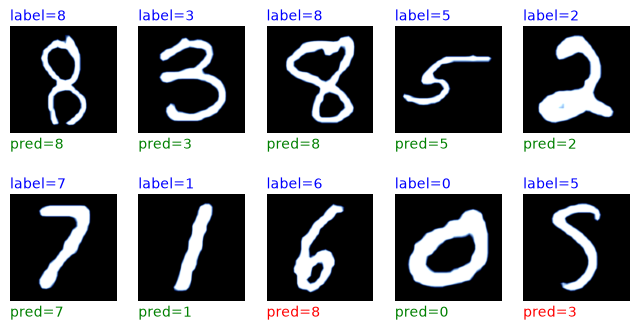

*Random Wrong Predictions from **scenario 1: fine-tune classifier**:*

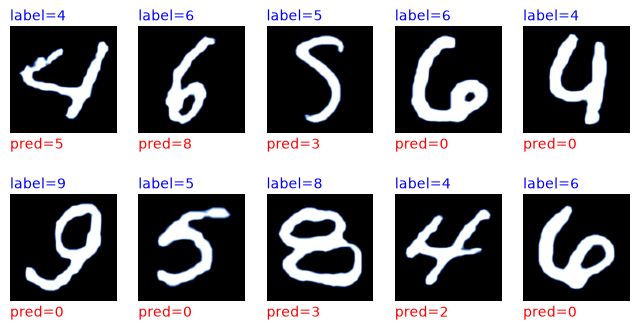

*Training Loss and Validation Accuracy from **scenario 1: fine-tune classifier**:*

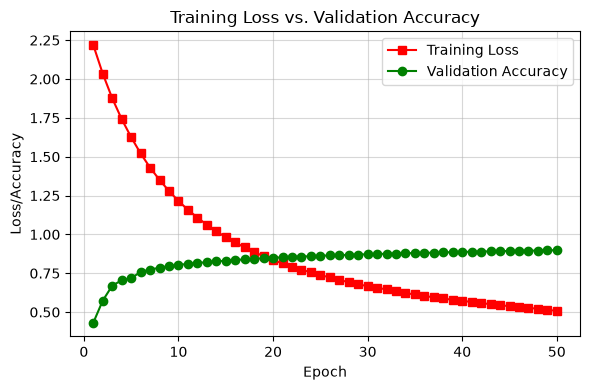

In [39]:
# Inferences for random images
analytics.test_predictions(experiment=experiment_classifier)
# Random wrong inferences
analytics.test_wrong_predictions(experiment=experiment_classifier)

# Training Loss and Validation Accuracy
analytics.loss_accuracy_plot(experiment=experiment_classifier)

## 26. Scenario 2: Fine-Tuning Classifier plus a few Layers <a id="26-scenario-2-fine-tuning-classifier-plus-a-few-layers"></a>

The final layer of classifier always needs to retrained because the original output was 1000 (for 1000 image classes) and new output needs to be 10 (for 10 digits). To accomodate this, the last layer needs to be redefined and retrained. On top of that, this second scenario gives an option to train a few more layers above the classifier layer. These are the features blocks. In this scenario you can set a number of these blocks to be fine-tuned.

In the example below, 3 features blocks are fine-tuned. That turns out 2.1 million parameters are to be fine-tuned and the remaining (about 2 million) parameters will not be touched during the training.

In [40]:
# Fine-tuning Scenario
experiment_classifier_plus = "scenario 2: fine-tune classifier plus"

# Setup Data and Backbone
weights = FinetuningWeights()
data = FinetuningDataModule(root="./data/finetune", weights=weights)
backbone_classifier_plus = FinetuningModule(
    weights=weights, num_layers_to_tune=3, learning_rate=learning_rate
)

# Run the trainer
trainer_classifier_plus = FinetuningTrainer(
    module=backbone_classifier_plus,
    data=data,
    experiment=experiment_classifier_plus,
    analytics=analytics,
    epochs=num_epochs,
)
classifier_plus_finetuned_model = trainer_classifier_plus.fit()

*`FinetuningWeights` is initialized. Metrics:*

| metric         | value                                                               |
|:---------------|:--------------------------------------------------------------------|
| name           | IMAGENET1K_V2                                                       |
| url            | https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth |
| num categories | 1000                                                                |
| mean           | [0.485, 0.456, 0.406]                                               |
| std            | [0.229, 0.224, 0.225]                                               |
| image size     | [224]                                                               |

*`FinetuningDataModule` is initialized. Metrics:*

| metric                | value           |
|:----------------------|:----------------|
| root                  | ./data/finetune |
| batch_size            | 256             |
| train_val_split       | (0.8, 0.2)      |
| train dataset samples | 192,000         |
| val dataset samples   | 48,000          |
| test dataset samples  | 40,000          |

*`FinetuningModule` is initialized. Metrics:*

| metric                                      | value              |
|:--------------------------------------------|:-------------------|
| model name                                  | mobilenet_v3_large |
| num feature extractor blocks                | 17                 |
| num classifier layers                       | 4                  |
| original model - total parameters           | 5,483,032          |
| original model - num feature parameters     | 2,971,952          |
| original model - num classifier parameters  | 2,511,080          |
| fine-tune model - total parameters          | 4,214,842          |
| fine-tune model - num feature parameters    | 2,971,952          |
| fine-tune model - num classifier parameters | 1,242,890          |
| fine-tune model - num parameters to tune    | 2,196,234          |
| fine-tune model - num parameters unchanged  | 2,018,608          |

*`FinetuningTrainier` fit():*

Training and Validation Started for: 'scenario 2: fine-tune classifier plus'.
On Device: mps

Epoch 1 | loss = 2.1771 | accuracy = 47.27%
Epoch 2 | loss = 1.8950 | accuracy = 58.64%
Epoch 3 | loss = 1.4854 | accuracy = 75.31%
Epoch 4 | loss = 1.1531 | accuracy = 73.86%
Epoch 5 | loss = 0.9173 | accuracy = 81.42%
Epoch 6 | loss = 0.7535 | accuracy = 83.61%
Epoch 7 | loss = 0.6393 | accuracy = 83.00%
Epoch 8 | loss = 0.5551 | accuracy = 89.03%
Epoch 9 | loss = 0.4943 | accuracy = 84.59%
Epoch 10 | loss = 0.4452 | accuracy = 75.85%
Epoch 11 | loss = 0.4056 | accuracy = 81.60%
Epoch 12 | loss = 0.3753 | accuracy = 89.55%
Epoch 13 | loss = 0.3488 | accuracy = 90.87%
Epoch 14 | loss = 0.3256 | accuracy = 91.11%
Epoch 15 | loss = 0.3059 | accuracy = 91.05%
Epoch 16 | loss = 0.2880 | accuracy = 91.54%
Epoch 17 | loss = 0.2732 | accuracy = 76.42%
Epoch 18 | loss = 0.2630 | accuracy = 88.36%
Epoch 19 | loss = 0.2520 | accuracy = 92.42%
Epoch 20 | loss = 0.2432 | accuracy = 83.56%
Epoch 21 | loss

### 26.1 Analytics: Scenario 2: Fine-Tuning Classifier Plus

On 30 epochs of training, this scenario reached 97.4% of accuracy on testing dataset. Of the two wrong predictions with the previous model (just classifier fine-tuning), this model got one right. It could identify a sloppily written 6, but the 5 was a bit more sloppy.

After a few epochs, this model lost a bit of accuracy before regaining. As before, big accuracy jumps came in the earlier epochs and then slowed down or drifted downward. It is difficult to have big gains once the accuracy reached ~96%. Also like before, big drops in training loss came earlier, but slowed down later on.

*Random Predictions from **scenario 2: fine-tune classifier plus**:*

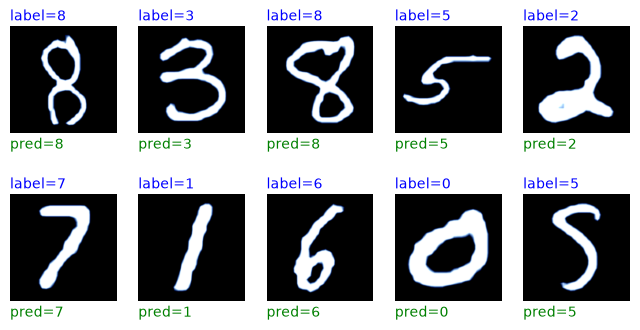

*Random Wrong Predictions from **scenario 2: fine-tune classifier plus**:*

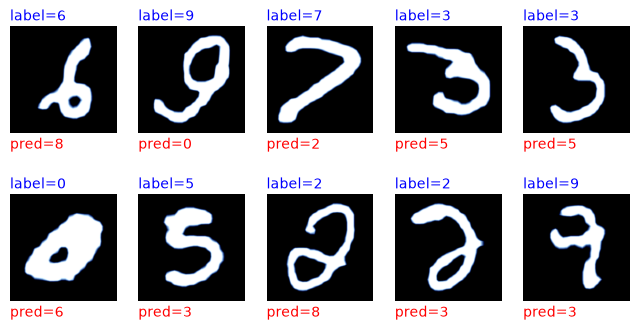

*Training Loss and Validation Accuracy from **scenario 2: fine-tune classifier plus**:*

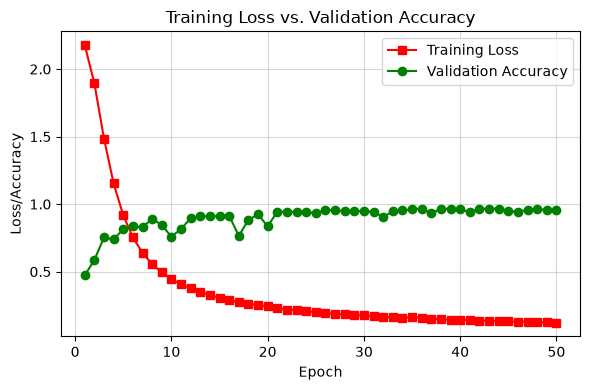

In [41]:
# Inferences for random images with Classifier Plus 3 layers fine-tuned model
analytics.test_predictions(experiment=experiment_classifier_plus)
# Random wrong inferences
analytics.test_wrong_predictions(experiment=experiment_classifier_plus)

# Training Loss and Validation Accuracy for Scenario 2
analytics.loss_accuracy_plot(experiment=experiment_classifier_plus)

## 27. Scenario 3: Fine-Tuning the Entire Model <a id="27-scenario-3-fine-tuning-the-entire-model"></a>

In this case, the entire model will be fine-tuned. We will start the 4.2 million of the original parameters (except the classifier layer will be new). Once the training is completed, all these parameters will have been tuned.

In [42]:
# Fine-tuning Scenario
experiment_full = "scenario 3: fine-tune full model"

# Setup Data and Backbone
weights = FinetuningWeights()
data = FinetuningDataModule(root="./data/finetune", weights=weights)
backbone_full = FinetuningModule(
    weights=weights, num_layers_to_tune=-1, learning_rate=learning_rate
)

# Run the trainer
trainer_full_model = FinetuningTrainer(
    module=backbone_full,
    data=data,
    experiment=experiment_full,
    analytics=analytics,
    epochs=num_epochs,
)
full_finetuned_model = trainer_full_model.fit()

*`FinetuningWeights` is initialized. Metrics:*

| metric         | value                                                               |
|:---------------|:--------------------------------------------------------------------|
| name           | IMAGENET1K_V2                                                       |
| url            | https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth |
| num categories | 1000                                                                |
| mean           | [0.485, 0.456, 0.406]                                               |
| std            | [0.229, 0.224, 0.225]                                               |
| image size     | [224]                                                               |

*`FinetuningDataModule` is initialized. Metrics:*

| metric                | value           |
|:----------------------|:----------------|
| root                  | ./data/finetune |
| batch_size            | 256             |
| train_val_split       | (0.8, 0.2)      |
| train dataset samples | 192,000         |
| val dataset samples   | 48,000          |
| test dataset samples  | 40,000          |

*`FinetuningModule` is initialized. Metrics:*

| metric                                      | value              |
|:--------------------------------------------|:-------------------|
| model name                                  | mobilenet_v3_large |
| num feature extractor blocks                | 17                 |
| num classifier layers                       | 4                  |
| original model - total parameters           | 5,483,032          |
| original model - num feature parameters     | 2,971,952          |
| original model - num classifier parameters  | 2,511,080          |
| fine-tune model - total parameters          | 4,214,842          |
| fine-tune model - num feature parameters    | 2,971,952          |
| fine-tune model - num classifier parameters | 1,242,890          |
| fine-tune model - num parameters to tune    | 4,214,842          |
| fine-tune model - num parameters unchanged  | 0                  |

*`FinetuningTrainier` fit():*

Training and Validation Started for: 'scenario 3: fine-tune full model'.
On Device: mps

Epoch 1 | loss = 2.1295 | accuracy = 57.90%
Epoch 2 | loss = 1.6407 | accuracy = 73.76%
Epoch 3 | loss = 0.9779 | accuracy = 90.62%
Epoch 4 | loss = 0.5542 | accuracy = 93.12%
Epoch 5 | loss = 0.3489 | accuracy = 94.93%
Epoch 6 | loss = 0.2466 | accuracy = 96.08%
Epoch 7 | loss = 0.1904 | accuracy = 96.64%
Epoch 8 | loss = 0.1570 | accuracy = 97.49%
Epoch 9 | loss = 0.1353 | accuracy = 97.67%
Epoch 10 | loss = 0.1190 | accuracy = 97.97%
Epoch 11 | loss = 0.1061 | accuracy = 97.87%
Epoch 12 | loss = 0.0974 | accuracy = 98.06%
Epoch 13 | loss = 0.0910 | accuracy = 98.12%
Epoch 14 | loss = 0.0842 | accuracy = 98.31%
Epoch 15 | loss = 0.0794 | accuracy = 98.18%
Epoch 16 | loss = 0.0750 | accuracy = 98.41%
Epoch 17 | loss = 0.0715 | accuracy = 98.27%
Epoch 18 | loss = 0.0680 | accuracy = 98.48%
Epoch 19 | loss = 0.0659 | accuracy = 98.49%
Epoch 20 | loss = 0.0631 | accuracy = 98.71%
Epoch 21 | loss = 0.

### 27.1 Analytics: Scenario 3: Fine-Tuning the Entire Model

In this scenario, weights in all the layers were allowed to be updated. Accuracy gains are big ending with a final number of 99.2%. Here, the model could predict both the sloppily written digits (6 and 5) correctly.

Here by epoch 10, the model has reached very high validation accuracy and very low training loss. From there on (until epoch 30), the changes were small but continued to increase the accuracy. At this point, the wrong predictions are mostly very sloppily written digits or some that could be easily confused or some digits like 0 with a slash through it (not many people write like this, hence not many samples like this to learn from).

*Random Predictions from **scenario 3: fine-tune full model**:*

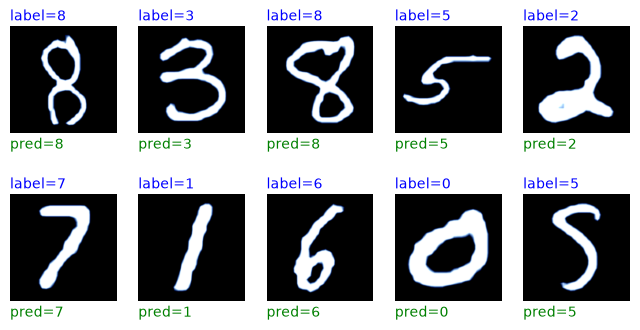

*Random Wrong Predictions from **scenario 3: fine-tune full model**:*

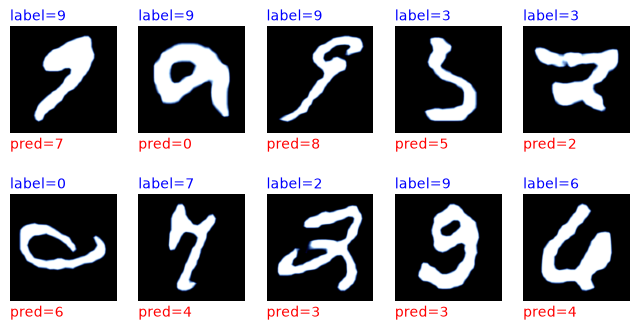

*Training Loss and Validation Accuracy from **scenario 3: fine-tune full model**:*

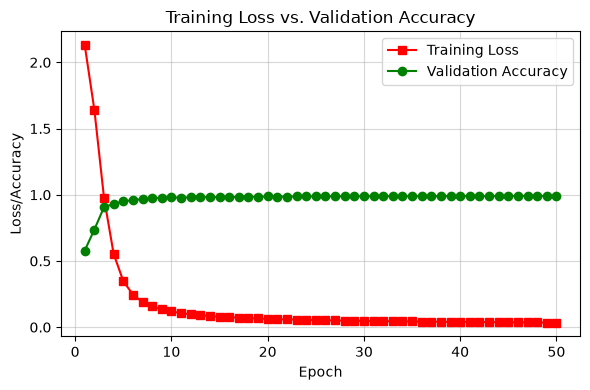

In [43]:
# Predictions for random images with entire model fine-tuned
analytics.test_predictions(experiment=experiment_full)
# Random wrong predictions
analytics.test_wrong_predictions(experiment=experiment_full)

# Training Loss and Validation Accuracy with Scenario 3 model
analytics.loss_accuracy_plot(experiment=experiment_full)

# IX. Conclusion <a id="ix-conclusion"></a>

In this project we have taken a pretrained image classifier model named MobileNetV3 with large weights as the backbone. Then that model has been re-purpsed from pure image classifier to a hand-written digit classier. For this fine-tuning, MNIST digits dataset has been used. After preparing datasets with appropriate transformations, dataloaders have been prepared for training. Fine-tuned the model in three different scenarios for 10-epochs each. Resulting new model has been tested against test dataset that the model has not seen before for final accuracy score.

Below various sets of wrong predictions made by all models are displayed. All three models provided wrong predictions to these hand-written digits. Looking at these hand-written digits, you can see why models (even humans) will find these samples are very sloppy, not just written differently. With this type samples, it is very difficult to achieve 100% accuracy with any model.


**10 Wrong predictions starting from index 5,000**

Here the wrong predictions seem to fall into these categories:

- Formally written 1s. People generally don't write 1s like they are printed. Most of the samples are just simple vertical lines. Formally written 1s do look like 2s. Model didn't have too many samples like this to learn from.

- Sloppy hand-writing: Rest of the samples among these wrong predictions fall into sloppy handwriting, at least not how most of the people write those samples.


*Random Wrong Predictions from **['scenario 1: fine-tune classifier', 'scenario 2: fine-tune classifier plus', 'scenario 3: fine-tune full model']**:*

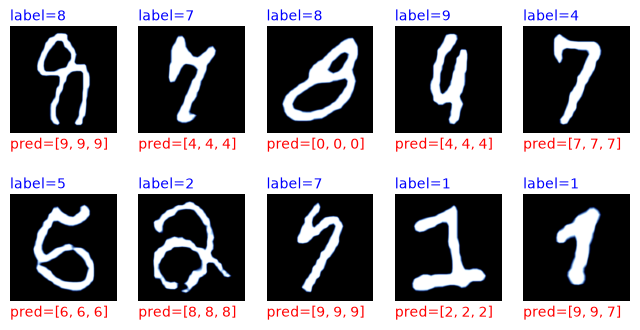

In [44]:
analytics.test_wrong_predictions_across_experiments(idx_start=5000)

**10 Wrong predictions starting from index 15,000**

- 0s with a slash through it seem to be identified as 8, because that's how they look, if there aren't many samples to learn from. Not many people write 0 like that.

- Stylized 1s and 2s seem to have been mis-identified.

- Bad/lazy handwriting and some extraneous pixels (ink) seems have made others hard to read.

*Random Wrong Predictions from **['scenario 1: fine-tune classifier', 'scenario 2: fine-tune classifier plus', 'scenario 3: fine-tune full model']**:*

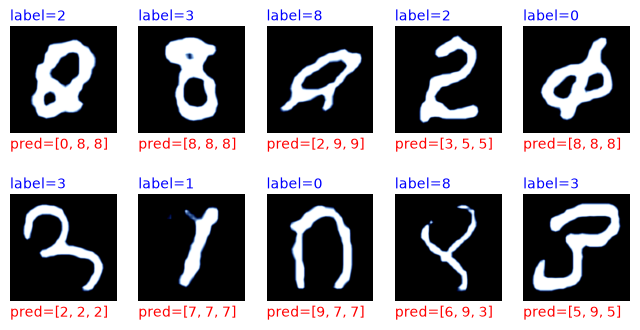

In [45]:
analytics.test_wrong_predictions_across_experiments(idx_start=15000)

**10 wrong predictions starting from index 25,000**

- 5's below are mis-labeled as 0 and 3. For one of the 5, part of the stroke is missing.

- Rest are covered above: sloppy handwriting, stylized 1s (not enough samples to learn from), etc.

*Random Wrong Predictions from **['scenario 1: fine-tune classifier', 'scenario 2: fine-tune classifier plus', 'scenario 3: fine-tune full model']**:*

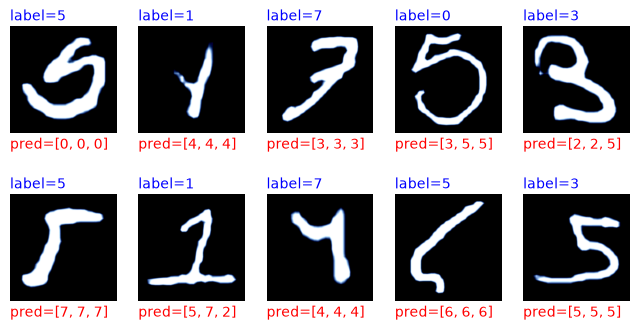

In [46]:
analytics.test_wrong_predictions_across_experiments(idx_start=25000)

## 28. Compare Approaches <a id="28-compare-approaches"></a>

Following is a plot for accuracies in models generated by the three fine-tuning experiments. Fine-tuning the full model resulted in accuracy upwards 98%. The first scenario of fine-tuning just one layer (this is the final classifier layer) yielded around 86% accuracy, which is still great because all the weights in all the previous layers (except the last one) are from the previous training from ImageNet. These weights were not touched in the current training/fine-tuning. And the scenario 2 of fine-tuning 3 more blocks of feature layers in addition to the last classifier layer resulted in accuracy in between: at around 94%.

In this case, fine-tuning more weights resulted in better accuracy. And 100% accuracy was not achieved because some of hand-written digits are hard to recognize even for humans. This can be seen from the mis-classified digits.

*Accuracy Comparison between experiments: **['scenario 1: fine-tune classifier', 'scenario 2: fine-tune classifier plus', 'scenario 3: fine-tune full model']**:*

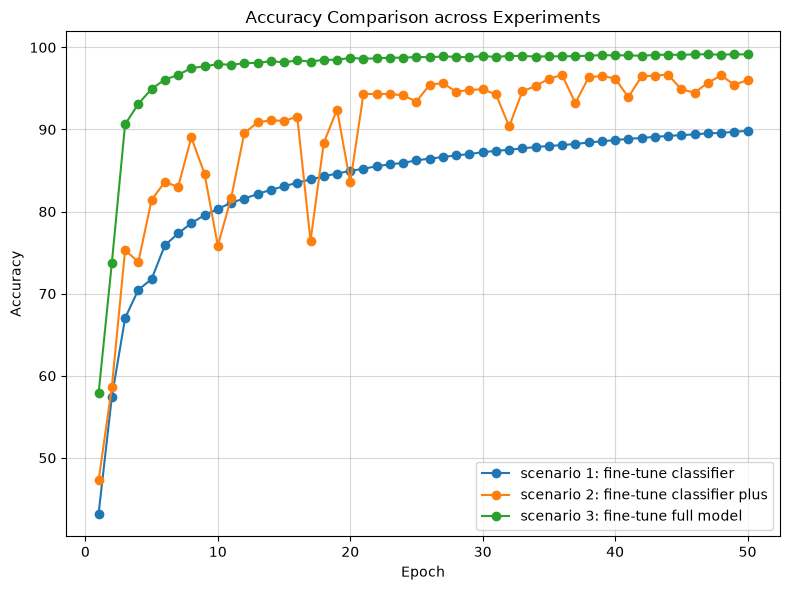

In [47]:
analytics.accuracy_compare_plot()